# Customer Financial Health Score — pipeline end-to-end

**Câu hỏi của điểm:** *Khách có quản lý được tài chính hiện tại và chống chịu được biến cố không?*

**Phương pháp:** Gradient Boosting (LightGBM) có ràng buộc đơn điệu cho các biến có chiều nghiệp vụ rõ, giải thích bằng **SHAP** (TreeSHAP có sẵn trong LightGBM).
Vì SHAP cộng tính trên log-odds, điểm 0–100 tách được chính xác thành điểm cộng/trừ của từng chỉ tiêu và từng nhóm.

**Dữ liệu:** bộ clean của nhóm `eda/clean_team/Clean_data-20261018T004659Z-1-001` (đã chuyển sang parquet bằng `load_team_clean.py`).

**Thiết kế thời gian** — biến chỉ dùng dữ liệu *trước* mốc, nhãn lấy *sau* mốc:

| Tập | Mốc | Nhãn "xấu" |
|---|---|---|
| Huấn luyện | 01/02, 01/04, 01/06, 01/08/2024 | HĐ trả góp ký trong 2 tháng sau mốc bị trễ ở 4 kỳ đầu hoặc bị xóa nợ |
| Chọn số cây và biến | 01/10/2024 | như trên |
| Kiểm chứng ngoài thời gian | 01/12/2024 | như trên (HĐ ký 12/2024–01/2025) |
| **Chấm điểm thật** | **05/06/2025** | — |
| Kiểm tra dữ liệu độc lập | 06–12/2025 | Cuộc gọi mã OWN* trong CALL: kiểm tra xem có phản ánh rủi ro không (kết quả: không, xem 9f) |

**Cấu trúc notebook theo đề Challenge 1:**

| Câu hỏi của đề | Mục | Bước pipeline |
|---|---|---|
| 1. Phân tích các yếu tố phản ánh sức khỏe tài chính | Câu 1 | 1–5: cấu hình, kiểm tra dữ liệu, **EDA các yếu tố ảnh hưởng → căn cứ chọn chỉ tiêu**, **mô tả biến đầu vào và feature engineering**, kiểm tra biến, phân tích từng biến |
| 2. Xây dựng điểm 0–100 | Câu 2 | huấn luyện, 6 chấm từng chỉ tiêu, 7 tổng hợp điểm |
| 3. Phân nhóm khách hàng có ý nghĩa kinh doanh | Câu 3 | hạng A–E, N, chân dung và hành động |
| 4. Yếu tố tác động tích cực / tiêu cực | Câu 4 | relative risk từ dữ liệu, SHAP toàn cục, 8 giải thích từng khách |
| 5. Bằng chứng phương pháp hợp lý | Câu 5 | 9 kiểm định, 10 xuất và theo dõi |

**Pipeline 10 bước** (mã nguồn: `solution/health_pipeline.py`, mỗi bước là một hàm):

| Bước | Hàm | Đầu ra |
|---|---|---|
| 1. Cấu hình | `config` | ngày chấm, cửa sổ, biến, tham số, ngưỡng, phiên bản |
| 2. Đọc và kiểm tra dữ liệu | `load_and_check` | khóa, trùng, kiểu, thiếu, quan hệ bảng |
| 3. Snapshot khách hàng | `build_snapshot` | mỗi khách một dòng tại ngày chấm, mức độ đầy đủ dữ liệu |
| 4. Tạo biến | `feature_engineering` | 57 chỉ tiêu theo 7 nhóm |
| 5. Kiểm tra biến | `validate_features` | mẫu số 0, giá trị bất hợp lý, biến trùng, độ đầy đủ |
| 6. Chấm từng chỉ tiêu | `score_features` | điểm chỉ tiêu 0–100 |
| 7. Tổng hợp điểm | `aggregate_scores` | điểm nhóm + Financial Health Score + hạng |
| 8. Giải thích | `explain_scores` | 3 lý do trừ điểm, 3 điểm mạnh |
| 9. Kiểm định | `validate_scorecard` | hiệu quả, logic, độ nhạy, bỏ từng nhóm, kiểm tra dữ liệu độc lập |
| 10. Xuất và theo dõi | `export_and_monitor` | file điểm có phiên bản, trôi dạt biến, lịch sử theo dõi |

## 0. Thiết lập

In [1]:
import os, sys, pathlib, warnings
HERE = pathlib.Path.cwd()
if HERE.name != "solution":
    HERE = HERE / "solution"
os.chdir(HERE); sys.path.insert(0, str(HERE))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import health_pipeline as hp
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 40, "display.width", 200, "display.float_format", lambda x: f"{x:,.4f}")
BAND_COLORS = {"A": "#2e7d32", "B": "#7cb342", "C": "#fbc02d", "D": "#f57c00", "E": "#c62828", "N": "#9e9e9e"}

# Câu 1 · Các yếu tố phản ánh sức khỏe tài chính
Phần này đi từ dữ liệu gốc → kiểm tra chất lượng → **biến đầu vào và cách tạo chỉ tiêu** → kiểm tra chỉ tiêu → **phân tích từng chỉ tiêu có thật sự tách được khách tốt/xấu không**.

## Bước 1 · Cấu hình (`config`)
Mọi tham số nằm ở một chỗ: ngày chấm, các mốc, định nghĩa nhãn, danh sách biến (nhóm, mô tả, chiều ràng buộc), tham số mô hình, thang điểm, ngưỡng hạng, phiên bản.
Chiều ràng buộc: **+1** biến càng lớn rủi ro không được giảm; **−1** biến càng lớn rủi ro không được tăng; **0** để mô hình tự học (quan hệ có thể không đơn điệu).

In [2]:
cfg = hp.config()
display(pd.Series({k: cfg[k] for k in ["version", "score_date", "dev_cutoffs", "valid_cutoff", "oot_cutoff", "mature_days",
                                       "label", "pdo", "base_score", "min_shap_share"]}, name="giá trị").to_frame())
VARS = pd.DataFrame([(k, *v) for k, v in cfg["variables"].items()], columns=["bien", "nhom", "mo_ta", "rang_buoc"])
display(VARS.groupby("nhom").agg(so_bien=("bien", "size"), vi_du=("mo_ta", lambda x: "; ".join(x[:3]))))

,giá trị
version,FH-GB-v1.1
score_date,2025-06-05
dev_cutoffs,"[2024-02-01, 2024-04-01, 2024-06-01, 2024-08-0..."
valid_cutoff,2024-10-01
oot_cutoff,2024-12-01
mature_days,125
label,Xấu = có HĐ trả góp ký trong 2 tháng sau mốc b...
pdo,15
base_score,50
min_shap_share,0.0050


,so_bien,vi_du
nhom,,
1. Thu nhập & ổn định,8,Thu nhập chính khai báo; Độ biến động thu nhập...
2. Cân đối thu–chi,1,Thu nhập còn lại sau tiền góp hàng tháng
3. Gánh nặng nợ,5,Số HĐ đang hoạt động; Số HĐ quay vòng (thẻ/hạn...
4. Lịch sử thanh toán,16,Lần trễ hạn gần nhất; Tổng số kỳ trễ hạn; Tỷ l...
5. Dự phòng tài chính,5,Tỷ lệ trả trước (CD/TW); Tiền trả trước / thu ...
6. Áp lực vay & độ tin cậy,19,Hạn mức công ty sẵn sàng cấp (gần nhất); Hạn m...
7. Kế hoạch & bảo vệ,2,Tỷ lệ HĐ có mua bảo hiểm khoản vay; HĐ gần nhấ...


**Đối chiếu 7 nhóm gợi ý với dữ liệu có sẵn**

| Nhóm gợi ý | Có trong dữ liệu | Không có (giới hạn) |
|---|---|---|
| 1. Thu nhập & độ ổn định | thu nhập khai báo, độ biến động, số lần đổi nghề/nguồn thu nhập | thu nhập ròng thực, thời gian làm việc |
| 2. Cân đối thu–chi | thu nhập còn lại sau tiền góp | chi tiêu, chi phí thiết yếu |
| 3. Gánh nặng nợ | số HĐ đang chạy, HĐ quay vòng, tiền góp/thu nhập, khoản vay/thu nhập | dư nợ thật, nợ ở tổ chức khác |
| 4. Lịch sử thanh toán | cờ trễ 4 kỳ đầu, chuỗi trễ, trễ 6/12 tháng, xóa nợ, thời gian từ lần trễ | số ngày quá hạn (DPD), dư nợ quá hạn |
| 5. Dự phòng tài chính | đại diện: tiền trả trước bằng tiền mặt | tiết kiệm, quỹ dự phòng |
| 6. Áp lực vay nợ | số lần xin vay/bị từ chối/tự hủy, hạn mức đề xuất và thay đổi hạn mức | số tổ chức đang vay, cơ cấu nợ |
| 7. Kế hoạch & bảo vệ | mua bảo hiểm khoản vay | tiết kiệm dài hạn, bảo hiểm khác |

Không dùng biến nhân khẩu học (tuổi, giới tính, vùng). Không dùng PAST_BEHAVIOR vì bảng này đã thuộc Engagement Score (hai điểm không dùng chung biến).
CALL chỉ có từ 01/2025 (sau mọi mốc huấn luyện) nên không dùng để huấn luyện; bước 9f kiểm tra xem có dùng được làm dữ liệu độc lập không.

### 1.1 Biến đầu vào (cột gốc của dữ liệu)
Cột gốc theo từ điển dữ liệu của ban tổ chức, tên cột sau khi làm sạch, và cách dùng trong điểm Health.

In [3]:
import importlib, feature_doc; importlib.reload(feature_doc)
raw = pd.DataFrame(feature_doc.RAW_INPUTS, columns=["Bảng", "Cột gốc", "Cột sau clean", "Ý nghĩa", "Cách dùng trong điểm Health"])
display(raw.style.hide(axis="index").set_properties(**{"text-align": "left"}))

Bảng,Cột gốc,Cột sau clean,Ý nghĩa,Cách dùng trong điểm Health
CONTRACT,SKP_CREDIT_CASE,case_id,Mã hồ sơ vay,Khóa; đếm số hồ sơ
CONTRACT,SKP_CLIENT,skp_client,Mã khách hàng,Gộp về cấp khách hàng
CONTRACT,NAME_CREDIT_STATUS,"status, is_signed, is_rejected, is_cancelled, is_writeoff","Trạng thái hồ sơ (Active, Finished, Rejected, Cancelled, Written off…)",Ký / bị từ chối / tự hủy / bị xóa nợ / tất toán
CONTRACT,PRODUCT,"product, is_revolving","Sản phẩm: CD, TW, CL, CW (trả góp); CC, BNPL (quay vòng)…",Tách HĐ trả góp (có lịch trả) và HĐ quay vòng
CONTRACT,APPLY / APPROVE / SIGN_CONTRACT_TIME,"t_apply, t_approve, t_sign, t_sign_filled","Thời điểm nộp, duyệt, ký",Lọc dữ liệu trước ngày chấm; tính cửa sổ 1/3/6/12 tháng
CONTRACT,AMT_CREDIT,amt_credit,Số tiền vay,"Gánh nặng nợ, tốc độ tăng nợ"
CONTRACT,PAYMENT_NUM,tenor,Số kỳ trả,Xác định HĐ còn đang chạy tại ngày chấm
CONTRACT,INIT_PAY,init_pay,"Tiền trả trước (CD, TW)",Dự phòng tài chính: khả năng trả trước bằng tiền mặt
CONTRACT,ANNUITY,annuity,Tiền góp hàng tháng,Nghĩa vụ trả nợ hàng tháng / thu nhập
CONTRACT,FIRST..FOURTH_DUE,"d1, d2, d3, d4",Cờ 0/1: kỳ 1–4 bị trễ hạn,Lịch sử thanh toán (chỉ dùng cho HĐ ký trước ngày chấm ≥ 125 ngày để 4 kỳ đã đến hạn)


### 1.2 EDA – các yếu tố ảnh hưởng tới sức khỏe tài chính (căn cứ chọn chỉ tiêu)
Trước khi tạo chỉ tiêu, tìm hiểu **điều gì phân biệt khách trả nợ tốt với khách gặp khó khăn**, rồi lấy đó làm căn cứ thiết kế chỉ tiêu ở mục 1.3.

- **Đơn vị phân tích:** từng **HĐ đã ký và đủ 4 kỳ thanh toán** (ký trước 01/02/2025), trên toàn bộ lịch sử.
- **Biến kết quả:** HĐ có trễ hạn ở bất kỳ kỳ nào trong 4 kỳ đầu, cùng định nghĩa "xấu" với nhãn huấn luyện.
- Mọi quan hệ dưới đây là **tương quan, không phải nhân quả**.

| # | Câu hỏi | Nhóm chỉ tiêu liên quan |
|---|---|---|
| 3.1 | Trễ hạn phân bố thế nào theo sản phẩm, theo kỳ, theo năm? | Bức tranh chung |
| 3.2 | Trạng thái HĐ (Finished, Paid off, Written off…) có dùng được không? | Rò rỉ thông tin |
| 3.3 | Trễ hạn trong quá khứ có lặp lại không? Gần đây hay đã lâu có khác không? | 4. Lịch sử thanh toán |
| 3.4 | Thành tích tốt, thâm niên dài có bảo vệ khách không? Vay dồn dập thì sao? | 6. Độ tin cậy tín dụng |
| 3.5 | Gánh nặng trả nợ và thu nhập ảnh hưởng thế nào? | 1. Thu nhập, 2. Thu–chi, 3. Gánh nặng nợ |
| 3.6 | Kỳ hạn, trả trước, bảo hiểm có liên quan không? | 5. Dự phòng, 7. Bảo vệ |
| 3.7 | Bị từ chối, hạn mức được chào có phản ánh rủi ro không? | 6. Áp lực vay & độ tin cậy |
| 3.8 | Nhân khẩu học có khác biệt không, và vì sao không dùng? | Công bằng |

In [4]:
import eda_reasoning
from features import connect as _connect
con_eda = _connect()
E = eda_reasoning.contract_eda(con_eda)

def rate_bar(ax, d, title, base=None, fmt="{:.1%}", rot=0):
    """Cột = tỷ lệ trễ của từng nhóm; số nhỏ dưới chân cột = số HĐ/KH."""
    d = d.dropna(subset=["ty_le_tre"])
    ax.bar(d.nhom.astype(str), d.ty_le_tre * 100, color="#3b6fb6", width=.65)
    for i, (v, n) in enumerate(zip(d.ty_le_tre, d.so_hd)):
        ax.text(i, v * 100, fmt.format(v), ha="center", va="bottom", fontsize=7.5)
        ax.text(i, 0, f"n={n / 1e3:,.0f}K" if n >= 1e3 else f"n={n:,.0f}", ha="center", va="bottom", fontsize=6.5, color="white")
    if base is not None:
        ax.axhline(base * 100, color="k", ls="--", lw=.8)
    ax.set_title(title, fontsize=9); ax.set_ylabel("% trễ hạn"); ax.tick_params(axis="x", labelsize=7.5, rotation=rot)

BASE = float(E["tong_quan"].ty_le_tre[0])
display(E["tong_quan"].rename(columns={"so_hd": "số HĐ đủ 4 kỳ", "so_kh": "số khách", "ty_le_tre": "tỷ lệ HĐ trễ hạn"})
        .style.format({"số HĐ đủ 4 kỳ": "{:,.0f}", "số khách": "{:,.0f}", "tỷ lệ HĐ trễ hạn": "{:.2%}"}).hide(axis="index"))

số HĐ đủ 4 kỳ,số khách,tỷ lệ HĐ trễ hạn
"2,759,040","812,709",2.02%


#### 3.1 Bức tranh trễ hạn

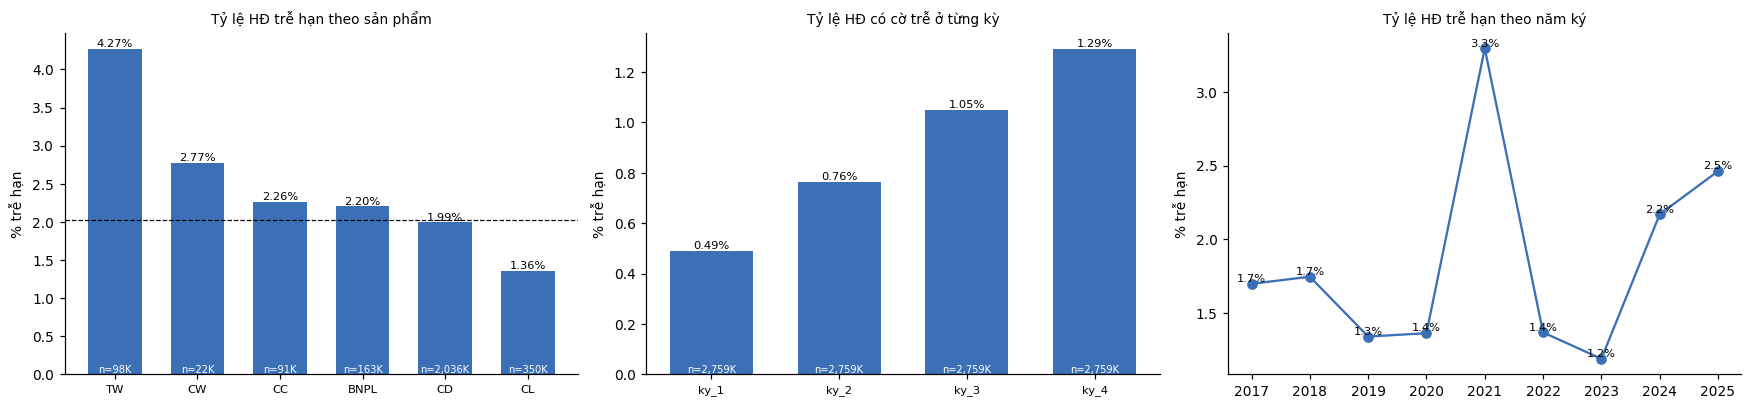

Trong các HĐ trễ kỳ 1, 50.6% vẫn trễ ở kỳ 4


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
rate_bar(axes[0], E["san_pham"], "Tỷ lệ HĐ trễ hạn theo sản phẩm", BASE, fmt="{:.2%}")
k = E["theo_ky"].T.reset_index(); k.columns = ["nhom", "ty_le_tre"]; k["so_hd"] = E["tong_quan"].so_hd[0]
rate_bar(axes[1], k, "Tỷ lệ HĐ có cờ trễ ở từng kỳ", fmt="{:.2%}")
y = E["theo_nam"]
axes[2].plot(y.nhom.astype(int), y.ty_le_tre * 100, "o-", color="#3b6fb6")
for x_, v in zip(y.nhom, y.ty_le_tre): axes[2].text(x_, v * 100, f"{v:.1%}", ha="center", va="bottom", fontsize=7.5)
axes[2].set_title("Tỷ lệ HĐ trễ hạn theo năm ký", fontsize=9); axes[2].set_ylabel("% trễ hạn")
plt.tight_layout(); plt.show()
print(f"Trong các HĐ trễ kỳ 1, {E['d1_va_d4']:.1%} vẫn trễ ở kỳ 4")

> **Insight 3.1 – bức tranh trễ hạn** (2.759.040 HĐ đủ 4 kỳ của 812.709 khách, tỷ lệ trễ 2,02%)
> - **Rủi ro khác nhau theo sản phẩm:** xe máy TW **4,27%**, CW 2,77%, thẻ CC 2,26%, BNPL 2,20%, điện máy CD 1,99%, vay tiền mặt CL **1,36%**. CL thấp nhất, có lẽ vì chỉ được duyệt cho khách đã có lịch sử tốt.
> - **Trễ hạn tích lũy dần qua các kỳ:** tỷ lệ HĐ có cờ trễ tăng từ 0,49% (kỳ 1) → 0,76% → 1,05% → **1,29% (kỳ 4)**. Một nửa (50,6%) HĐ trễ kỳ 1 vẫn trễ ở kỳ 4.
>   → *Căn cứ:* không chỉ đếm "có / không trễ" mà cần đo **mức độ và độ kéo dài**: `max_late_streak` (chuỗi trễ liên tiếp), `late_rate_last3`, `n_inst_late_6m`, `n_inst_late_12m`.
> - **Theo năm ký:** năm 2021 tăng vọt lên **3,3%** (thời kỳ Covid); 2024–2025 tăng trở lại (2,2–2,5%). Rủi ro phụ thuộc chu kỳ kinh tế.
>   → *Căn cứ:* mô hình phải được kiểm chứng **theo thời gian** (huấn luyện 5 mốc 2024, kiểm chứng 12/2024), không chỉ chia ngẫu nhiên.

#### 3.2 Trạng thái hợp đồng và vấn đề rò rỉ thông tin

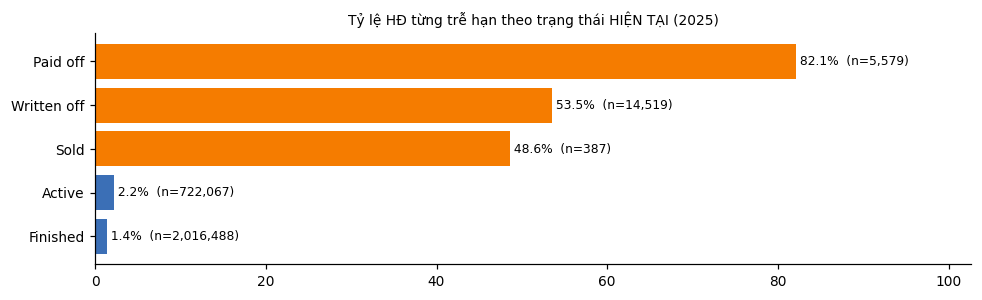

In [6]:
st = E["trang_thai"]
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.barh(st.nhom[::-1], st.ty_le_tre[::-1] * 100,
        color=["#f57c00" if s in ("Paid off", "Written off", "Sold") else "#3b6fb6" for s in st.nhom[::-1]])
for i, (v, n) in enumerate(zip(st.ty_le_tre[::-1], st.so_hd[::-1])):
    ax.text(v * 100, i, f" {v:.1%}  (n={n:,.0f})", va="center", fontsize=8)
ax.set_xlim(0, st.ty_le_tre.max() * 125); ax.set_title("Tỷ lệ HĐ từng trễ hạn theo trạng thái HIỆN TẠI (2025)", fontsize=9)
plt.tight_layout(); plt.show()

> **Insight 3.2 – trạng thái hợp đồng là *kết quả*, không phải *nguyên nhân***
> - **Paid off: 82,1% từng trễ hạn**, Written off 53,5%, Sold 48,6%; trong khi Finished chỉ 1,35% và Active 2,2%. "Paid off" là tất toán **sau khi đã gặp sự cố**, không phải dấu hiệu tốt.
> - Đây là trạng thái **tại 2025**. Một HĐ cũ chuyển sang Written off *sau* mốc huấn luyện (2024) sẽ làm lộ thông tin tương lai cho mô hình.
>
> → *Căn cứ:* **không dùng trạng thái HĐ hiện tại làm chỉ tiêu.** Hai chỉ tiêu ứng viên có dùng trạng thái (`n_clean_finished`, `ever_writeoff`) **không có trong 35 biến của mô hình cuối** (bị loại ở bước kiểm tra trùng thông tin và chọn biến theo SHAP). Lịch sử trả nợ chỉ dựa trên cờ trễ của các HĐ đã đủ 4 kỳ **trước mốc**.

#### 3.3 Lịch sử trả nợ: trễ hạn có lặp lại không?
Xét các HĐ **từ HĐ thứ 2 trở đi** của mỗi khách: HĐ hiện tại có trễ không, tùy theo những gì đã xảy ra ở các HĐ **trước đó**.

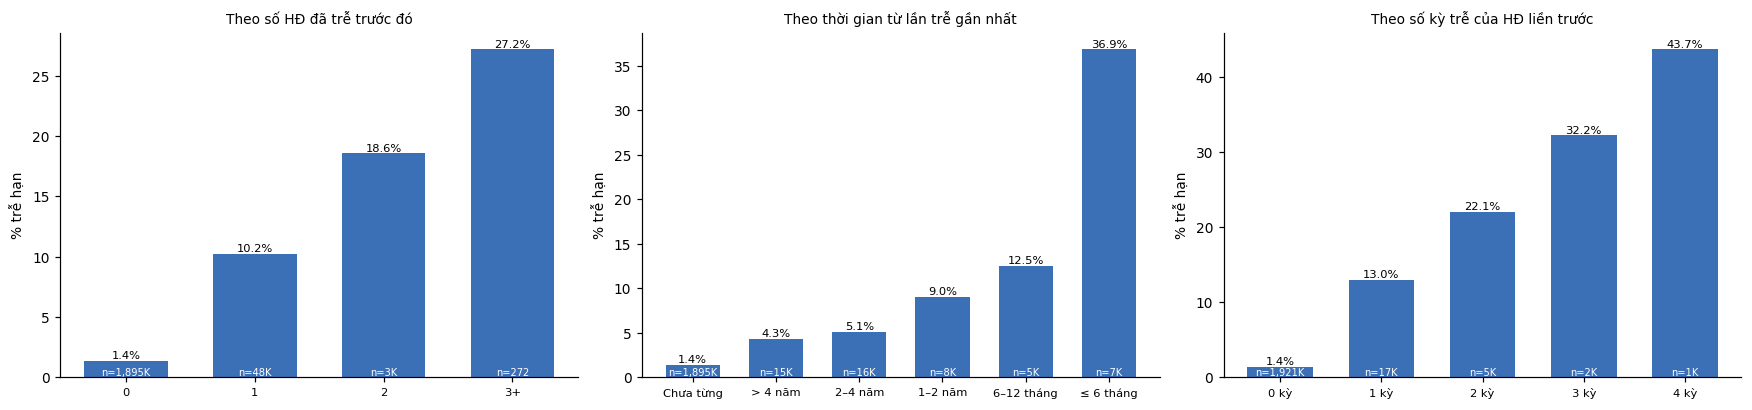

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
rate_bar(axes[0], E["so_hd_tre_truoc"], "Theo số HĐ đã trễ trước đó")
rate_bar(axes[1], E["lan_tre_gan_nhat"], "Theo thời gian từ lần trễ gần nhất")
rate_bar(axes[2], E["muc_do_hd_truoc"], "Theo số kỳ trễ của HĐ liền trước")
plt.tight_layout(); plt.show()

> **Insight 3.3 – trễ hạn có tính lặp lại (yếu tố tiêu cực mạnh nhất)**
>
> | Số HĐ đã trễ trước đó | 0 | 1 | 2 | ≥ 3 |
> |---|---|---|---|---|
> | Tỷ lệ trễ HĐ hiện tại | 1,4% | **10,2%** | **18,6%** | **27,2%** |
>
> - Chỉ một lần trễ đã làm rủi ro tăng khoảng **7 lần**.
> - **Độ gần đây quyết định mức nguy hiểm:** lần trễ gần nhất ≤ 6 tháng → **36,9%**; 6–12 tháng 12,5%; 1–2 năm 9,0%; 2–4 năm 5,1%; > 4 năm 4,3%. Rủi ro "phai dần" nhưng vẫn cao hơn khách chưa từng trễ (1,4%).
> - **Mức độ:** HĐ liền trước trễ 1 kỳ → 13,0%; trễ cả 4 kỳ → **43,7%**.
>
> → *Căn cứ:* nhóm **4. Lịch sử thanh toán** cần đủ 3 khía cạnh:
> - **số lần / tỷ lệ:** `n_due_total`, `on_time_rate`, `n_on_time`;
> - **độ gần đây:** `days_since_overdue`, `n_inst_late_6m`, `n_inst_late_12m`, `late_rate_last3`;
> - **mức độ:** `max_late_streak`, `n_consec2_late`.
>
> Các quan hệ đều **đơn điệu** → áp ràng buộc đơn điệu trong LightGBM (`on_time_rate` −1, `n_inst_late_*` +1, `days_since_overdue` −1…).

#### 3.4 Độ bền: thành tích tốt và thâm niên có bảo vệ khách không?

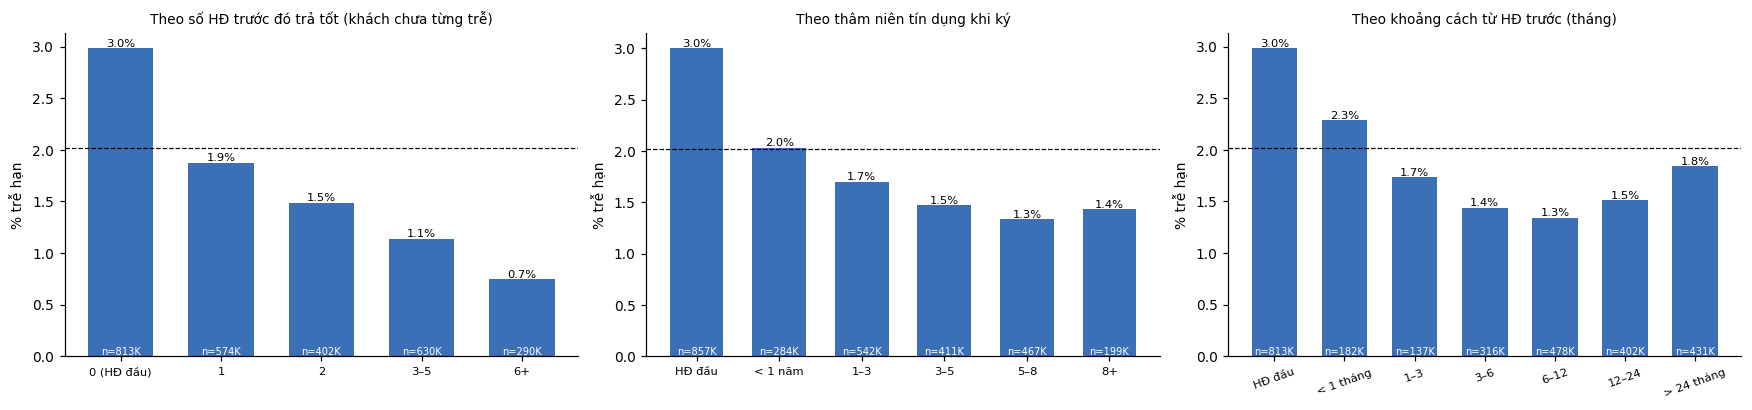

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
rate_bar(axes[0], E["so_hd_tot_truoc"], "Theo số HĐ trước đó trả tốt (khách chưa từng trễ)", BASE)
rate_bar(axes[1], E["tham_nien"], "Theo thâm niên tín dụng khi ký", BASE)
rate_bar(axes[2], E["nhip_vay"], "Theo khoảng cách từ HĐ trước (tháng)", BASE, rot=20)
plt.tight_layout(); plt.show()

> **Insight 3.4 – độ bền và nhịp vay (yếu tố tích cực mạnh nhất)**
> - **Thành tích trả tốt bảo vệ rõ ràng** (khách chưa từng trễ): HĐ đầu tiên 3,0% → sau 1 HĐ tốt 1,9% → 2 HĐ 1,5% → 3–5 HĐ 1,1% → **≥ 6 HĐ 0,7%**.
> - **Thâm niên:** HĐ đầu 3,0%, giảm còn khoảng 1,3–1,5% khi khách có từ 3 năm quan hệ tín dụng.
> - **Nhịp vay hình chữ U:** vay **dồn dập** (< 1 tháng sau HĐ trước) 2,3%; quay lại sau 6–12 tháng thấp nhất 1,3%; **quá lâu mới quay lại** (> 24 tháng) tăng lên 1,8%.
>
> → *Căn cứ:*
> - độ bền: `n_on_time`, `n_signed`, `history_years`;
> - nhịp vay: `days_since_last_signed`, `days_since_last_apply` — **không ép chiều** vì quan hệ hình chữ U;
> - khách chưa có HĐ nào đủ 4 kỳ là nhóm rủi ro cao nhất và ít bằng chứng nhất → tách thành hạng **N · Chưa đủ lịch sử trả nợ**.

#### 3.5 Gánh nặng trả nợ và thu nhập
`PTI` (payment-to-income) = tiền góp hàng tháng của HĐ ÷ thu nhập khai báo **khi nộp hồ sơ**.

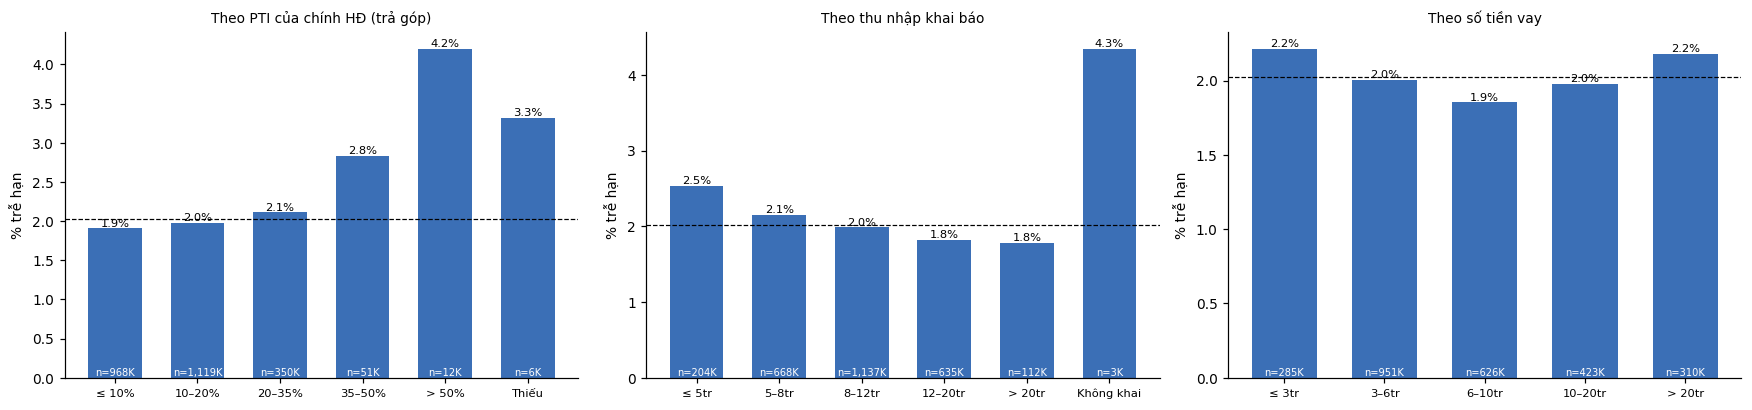

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
rate_bar(axes[0], E["pti"], "Theo PTI của chính HĐ (trả góp)", BASE)
rate_bar(axes[1], E["thu_nhap"], "Theo thu nhập khai báo", BASE)
rate_bar(axes[2], E["so_tien_vay"], "Theo số tiền vay", BASE)
plt.tight_layout(); plt.show()

> **Insight 3.5 – gánh nặng trả nợ và thu nhập**
> - **PTI:** đến 35% gần như không đổi (1,9–2,1%), nhưng **35–50% → 2,8%** và **> 50% → 4,2%** (gấp đôi). Gánh nặng nợ chỉ thành rủi ro khi **vượt ngưỡng** → quan hệ phi tuyến.
> - **Thu nhập khai báo:** tác động nhẹ, từ 2,5% (≤ 5 triệu) xuống 1,8% (> 20 triệu). Nhóm **không khai thu nhập** rủi ro gấp đôi (4,3%).
> - **Số tiền vay:** gần như không ảnh hưởng (1,9–2,2% ở mọi mức).
>
> → *Căn cứ:*
> - đo gánh nặng **cộng dồn** của các HĐ đang chạy: `active_annuity_income` (tiền góp/thu nhập), `active_credit_income`, `residual_income` (thu nhập còn lại), `n_active_revolving`;
> - **không ép chiều** (có ngưỡng); `income` giữ giá trị thiếu để mô hình học tín hiệu "không khai thu nhập";
> - độ ổn định thu nhập: `inc_cv`, `inc_vs_peak`, `inc_growth`, `n_income_types`, `income_years_declared`.
>
> **Giới hạn:** ở cấp khách, gánh nặng nợ cao lại đi cùng rủi ro *thấp* hơn (xem RR ở Câu 4) vì khách được duyệt vay nhiều là khách đã qua thẩm định — tương quan do chọn lọc. Đây là lý do nhóm 1–3 đóng góp ít khi bỏ khỏi mô hình (bước 9d).

#### 3.6 Đặc điểm khoản vay: kỳ hạn, trả trước, bảo hiểm

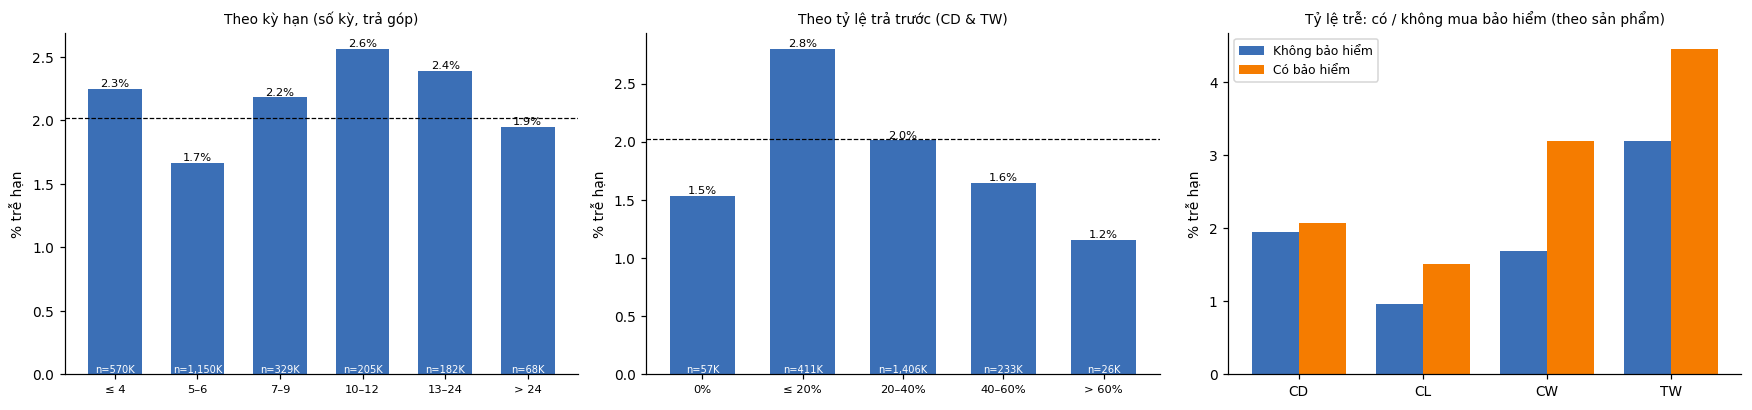

san_pham,khong_bao_hiem,co_bao_hiem
CD,1.94%,2.06%
CL,0.97%,1.51%
CW,1.68%,3.19%
TW,3.19%,4.45%


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
rate_bar(axes[0], E["ky_han"], "Theo kỳ hạn (số kỳ, trả góp)", BASE)
rate_bar(axes[1], E["tra_truoc"], "Theo tỷ lệ trả trước (CD & TW)", BASE)
b = E["bao_hiem"]; x = np.arange(len(b)); w = .38
axes[2].bar(x - w / 2, b.khong_bao_hiem * 100, w, label="Không bảo hiểm", color="#3b6fb6")
axes[2].bar(x + w / 2, b.co_bao_hiem * 100, w, label="Có bảo hiểm", color="#f57c00")
axes[2].set_xticks(x); axes[2].set_xticklabels(b.san_pham); axes[2].legend(fontsize=8)
axes[2].set_title("Tỷ lệ trễ: có / không mua bảo hiểm (theo sản phẩm)", fontsize=9); axes[2].set_ylabel("% trễ hạn")
plt.tight_layout(); plt.show()
display(b.style.format({"khong_bao_hiem": "{:.2%}", "co_bao_hiem": "{:.2%}"}).hide(axis="index"))

> **Insight 3.6 – đặc điểm khoản vay**
> - **Kỳ hạn:** không có xu hướng rõ (1,7–2,6%).
> - **Tỷ lệ trả trước (CD & TW):** trả trước càng nhiều càng an toàn: ≤ 20% → **2,8%**, > 60% → **1,2%**. Nhóm 0% thấp (1,5%), nhiều khả năng do chương trình trả góp 0% chỉ dành cho khách tốt.
>   → *Căn cứ:* nhóm **5. Dự phòng tài chính** (khả năng trả trước bằng tiền mặt là dấu hiệu có tích lũy): `down_payment_ratio`, `init_pay_income`, `avg_init_pay`, `max_init_pay_24m`. Nhóm này đóng góp 14,7% tổng |SHAP|, lớn thứ hai trong mô hình.
> - **Bảo hiểm khoản vay:** trong *cùng một sản phẩm*, HĐ có bảo hiểm lại trễ **nhiều hơn** (TW 4,5% so với 3,2%; CL 1,5% so với 1,0%; CW 3,2% so với 1,7%), có thể do **tự chọn lọc ngược** (khách tự biết mình rủi ro thì mua bảo hiểm). Nhưng ở cấp khách, khách mua bảo hiểm nhiều lại rủi ro thấp hơn (RR 0,72 ở Câu 4) vì bảo hiểm phổ biến ở sản phẩm an toàn.
>   → *Căn cứ:* `pct_insured2` (nhóm **7. Bảo vệ**) **không ép chiều**, để mô hình tự học quan hệ có điều kiện.

#### 3.7 Mức độ được duyệt và đánh giá của bên cho vay (cấp khách hàng)
Gộp về **cấp khách**: khách có HĐ đủ 4 kỳ được xem là "có vấn đề" nếu **ít nhất một** HĐ từng trễ.

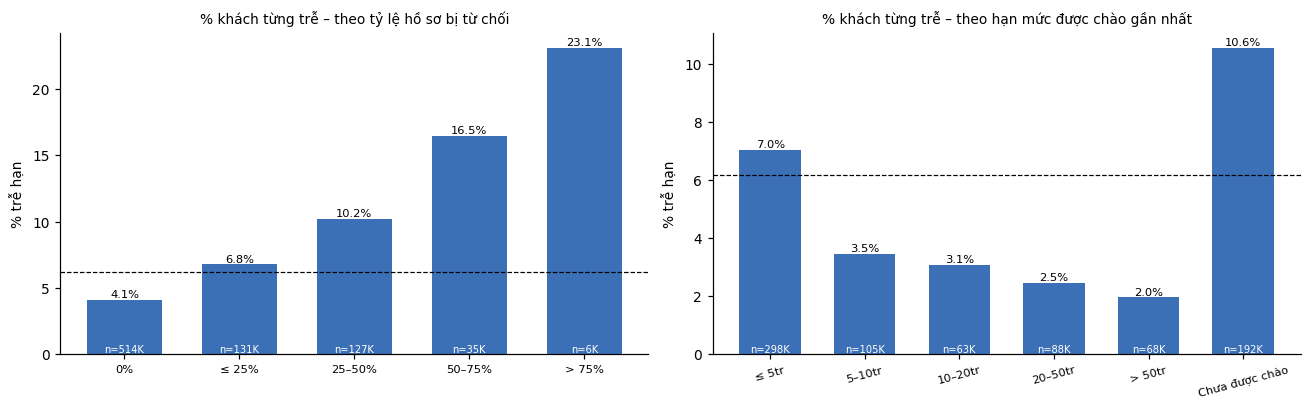

Khách có HĐ đủ 4 kỳ: 812,709 | tỷ lệ khách từng trễ: 6.19%


In [11]:
BASE_C = float(E["kh_tong_quan"].ty_le_kh_tung_tre[0])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
rate_bar(axes[0], E["ty_le_tu_choi"], "% khách từng trễ – theo tỷ lệ hồ sơ bị từ chối", BASE_C)
rate_bar(axes[1], E["max_offer"], "% khách từng trễ – theo hạn mức được chào gần nhất", BASE_C, rot=15)
plt.tight_layout(); plt.show()
print(f"Khách có HĐ đủ 4 kỳ: {int(E['kh_tong_quan'].so_kh[0]):,} | tỷ lệ khách từng trễ: {BASE_C:.2%}")

> **Insight 3.7 – được duyệt và đánh giá của bên cho vay** (812.709 khách, 6,19% từng trễ)
>
> | Tỷ lệ hồ sơ bị từ chối | 0% | ≤ 25% | 25–50% | 50–75% | > 75% |
> |---|---|---|---|---|---|
> | % khách từng trễ | 4,1% | 6,8% | 10,2% | 16,5% | **23,1%** |
>
> - **Bị từ chối là tín hiệu rủi ro rất mạnh**: bên cho vay từng từ chối thường có lý do.
> - **Hạn mức bên cho vay chào (MAX_OFFER)** phản ánh đánh giá năng lực của chính công ty: ≤ 5 triệu → 7,0%; > 50 triệu → **2,0%**; **chưa từng được chào → 10,6%**.
>
> → *Căn cứ:* nhóm **6. Áp lực vay & độ tin cậy**: `refused_ratio` (+1), `last_app_rejected` (+1), `n_refused_12m`, `max_offer` (−1, giữ thiếu = chưa được chào), `max_offer_12m`, `offer_change_6m`, `n_offers_12m`. Đây là nhóm quan trọng nhất của mô hình (57,7% tổng |SHAP|; bỏ nhóm này AUC giảm 0,020).

#### 3.8 Nhân khẩu học

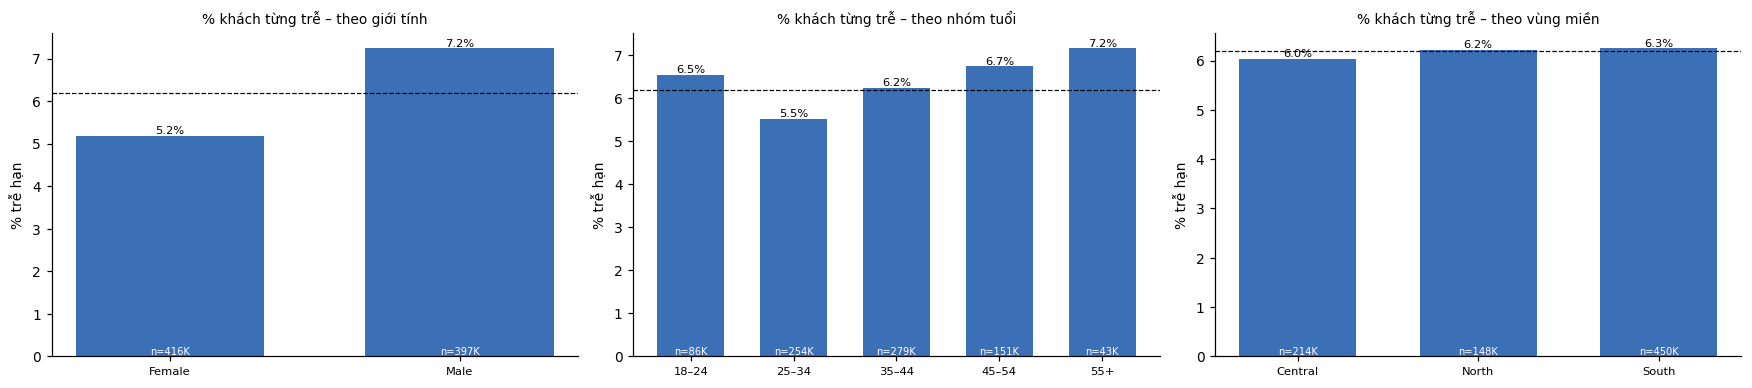

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
for ax, (k, t) in zip(axes, [("nhan_khau_gender", "giới tính"), ("nhan_khau_age", "nhóm tuổi"), ("nhan_khau_region", "vùng miền")]):
    d = E[k][E[k].so_hd > 1000]
    rate_bar(ax, d, f"% khách từng trễ – theo {t}", BASE_C)
plt.tight_layout(); plt.show()

> **Insight 3.8 – nhân khẩu học**
> - Có chênh lệch: **nam 7,2%** so với nữ 5,2%; tuổi 55+ là 7,2%, 25–34 là 5,5%; vùng miền gần như không khác (6,0–6,3%).
> - Đề bài yêu cầu *không dùng nhân khẩu học để xác định rủi ro khi không có đủ bằng chứng*. Các chênh lệch này có thể đến từ **hành vi** (sản phẩm vay, lịch sử) chứ không phải từ chính giới tính hay tuổi.
>
> → *Căn cứ:* **loại** giới tính, tuổi, vùng miền, học vấn, số con khỏi chỉ tiêu.

#### 3.9 Từ insight đến chỉ tiêu

| # | Insight (bằng chứng) | Chỉ tiêu trong mô hình | Chiều / xử lý |
|---|---|---|---|
| 1 | Trễ lặp lại: 1 HĐ trễ trước đó → rủi ro ×7; ≥ 3 HĐ → 27% | `n_due_total`, `on_time_rate`, `n_on_time` | ↑ / ↓, ràng buộc đơn điệu |
| 2 | Trễ ≤ 6 tháng → 37%; > 4 năm → 4% | `days_since_overdue`, `n_inst_late_6m`, `n_inst_late_12m`, `late_rate_last3` | ↓ / ↑ |
| 3 | Mức độ: HĐ trước trễ 1 kỳ → 13%, 4 kỳ → 44%; một nửa HĐ trễ kỳ 1 vẫn trễ kỳ 4 | `max_late_streak`, `n_consec2_late` | ↑ |
| 4 | Trạng thái HĐ là kết quả, gây rò rỉ (Paid off 82% từng trễ) | **Không dùng trạng thái** trong mô hình cuối | – |
| 5 | Mỗi HĐ trả tốt giảm rủi ro (3,0% → 0,7%); thâm niên dài an toàn hơn | `n_on_time`, `n_signed`, `history_years` | ↓ |
| 6 | Nhịp vay hình chữ U | `days_since_last_signed`, `days_since_last_apply`, `n_apply_6m` | không ép chiều |
| 7 | Bị từ chối 0% → 4,1%; > 75% → 23,1% | `refused_ratio`, `last_app_rejected`, `n_refused_12m` | ↑ |
| 8 | PTI > 50% → rủi ro gấp đôi (có ngưỡng) | `active_annuity_income`, `active_credit_income`, `residual_income`, `n_active_revolving` | không ép chiều |
| 9 | Không khai thu nhập → 4,3%; thu nhập cao an toàn hơn nhẹ | `income` (giữ thiếu), `inc_cv`, `inc_vs_peak`, `inc_growth`, `n_income_types` | không ép chiều |
| 10 | MAX_OFFER > 50 triệu → 2,0%; chưa được chào → 10,6% | `max_offer`, `max_offer_12m`, `offer_change_6m`, `n_offers_12m` | ↓ |
| 11 | Trả trước càng nhiều càng an toàn (≤ 20% → 2,8%; > 60% → 1,2%) | `down_payment_ratio`, `init_pay_income`, `avg_init_pay`, `max_init_pay_24m` | không ép chiều (nhóm 0% đặc biệt) |
| 12 | Bảo hiểm: ngược chiều giữa cấp HĐ và cấp khách | `pct_insured2` | không ép chiều |
| 13 | HĐ đầu tiên (chưa có lịch sử) rủi ro 3,0%, cao nhất | hạng **N · Chưa đủ lịch sử trả nợ** | tách riêng |
| 14 | Nhân khẩu học có chênh lệch nhưng không được phép dùng | **Loại** | – |
| 15 | Rủi ro thay đổi theo năm (2021, 2024–2025) | kiểm chứng ngoài thời gian 12/2024 | – |

Các insight trên được **kiểm định lại trên đúng quần thể huấn luyện** ở mục 1.4 (AUC đơn biến, tỷ lệ xấu theo nhóm giá trị) và bằng relative risk ở Câu 4.

### 1.3 Feature engineering — 57 chỉ tiêu theo 7 nhóm
**Nguyên tắc chung**
- **Cấp khách hàng tại một thời điểm:** mọi chỉ tiêu được gộp từ nhiều hồ sơ/HĐ về một dòng cho mỗi khách, *chỉ dùng dữ liệu trước ngày chấm*.
- **Độ chín của lịch sử trả nợ:** cờ FIRST..FOURTH_DUE là trạng thái cuối cùng của dữ liệu, nên chỉ dùng cho HĐ trả góp ký trước ngày chấm ít nhất 125 ngày (4 kỳ đã đến hạn) → tránh rò rỉ thông tin tương lai.
- **HĐ đang chạy:** HĐ trả góp đã ký và chưa hết kỳ hạn (ngày ký + số kỳ × 30 ngày > ngày chấm), hoặc HĐ quay vòng đang Active.
- **Cửa sổ thời gian:** 1, 3, 6, 12, 24 tháng và 3 năm, để đo cả *mức độ* và *xu hướng gần đây*.
- **Tỷ lệ:** mẫu số bằng 0 → để trống (xử lý ở bước 5), không thay bằng 0.
- **Chiều ràng buộc:** +1 = càng lớn càng rủi ro, −1 = càng lớn càng an toàn, 0 = để mô hình học (quan hệ có thể hình chữ U).

In [13]:
fe = pd.DataFrame([(cfg["variables"][v][0], v, cfg["variables"][v][1], *feature_doc.FEATURE_DOC[v], cfg["variables"][v][2])
                   for v in cfg["variables"]],
                  columns=["Nhóm", "Mã biến", "Chỉ tiêu", "Cột nguồn", "Công thức", "Cửa sổ", "Lý do nghiệp vụ", "Ràng buộc"])
fe.to_csv(cfg["out"] / "feature_dictionary.csv", index=False, encoding="utf-8-sig")
for g, t in fe.groupby("Nhóm"):
    display(Markdown(f"**{g}** — {len(t)} chỉ tiêu"))
    display(t.drop(columns="Nhóm").style.hide(axis="index").set_properties(**{"text-align": "left"}))

**1. Thu nhập & ổn định** — 8 chỉ tiêu

Mã biến,Chỉ tiêu,Cột nguồn,Công thức,Cửa sổ,Lý do nghiệp vụ,Ràng buộc
income,Thu nhập chính khai báo,inc_main,Thu nhập chính trên hồ sơ gần nhất,toàn bộ lịch sử,Nguồn tiền để trả nợ,0
inc_cv,Độ biến động thu nhập khai báo (3 năm),inc_main,Độ lệch chuẩn / trung bình thu nhập khai báo qua các hồ sơ,3 năm,Thu nhập biến động mạnh = nguồn tiền kém ổn định,0
n_income_values,Số mức thu nhập khác nhau đã khai,inc_main,Số mức thu nhập khác nhau đã khai,3 năm,Thay đổi thu nhập thường xuyên,0
inc_growth,Thu nhập mới nhất / cũ nhất (3 năm),inc_main,Thu nhập hồ sơ mới nhất / hồ sơ cũ nhất,3 năm,Thu nhập tăng hay giảm,0
inc_vs_peak,Thu nhập mới nhất / cao nhất,inc_main,Thu nhập mới nhất / thu nhập cao nhất từng khai,3 năm,Đang ở dưới đỉnh thu nhập = có thể vừa mất thu nhập,0
n_professions,Số nghề nghiệp đã khai,profession,Số mã nghề nghiệp khác nhau,3 năm,Đổi nghề nhiều = công việc kém ổn định,0
n_income_types,Số loại nguồn thu nhập đã khai,income_type,Số loại nguồn thu nhập khác nhau,3 năm,Đổi loại thu nhập (lương ↔ tự doanh…),0
income_years_declared,Số năm có khai báo thu nhập,"t_apply, inc_main",Số năm từ hồ sơ có thu nhập đầu tiên,3 năm,Thời gian có thu nhập được ghi nhận,0


**2. Cân đối thu–chi** — 1 chỉ tiêu

Mã biến,Chỉ tiêu,Cột nguồn,Công thức,Cửa sổ,Lý do nghiệp vụ,Ràng buộc
residual_income,Thu nhập còn lại sau tiền góp hàng tháng,"inc_main, annuity",Thu nhập − tổng tiền góp hàng tháng của các HĐ đang chạy,tại ngày chấm,Tiền còn lại sau khi trả nợ (dữ liệu không có chi tiêu sinh hoạt),0


**3. Gánh nặng nợ** — 5 chỉ tiêu

...

Mã biến,Chỉ tiêu,Cột nguồn,Công thức,Cửa sổ,Lý do nghiệp vụ,Ràng buộc
down_payment_ratio,Tỷ lệ trả trước (CD/TW),"init_pay, amt_credit","Trung bình trả trước / (khoản vay + trả trước), HĐ CD/TW",toàn bộ lịch sử,Có tiền mặt để trả trước = có tích lũy,0
init_pay_income,Tiền trả trước / thu nhập,"init_pay, inc_main",Tiền trả trước HĐ CD/TW gần nhất / thu nhập,HĐ gần nhất,Quy mô tích lũy so với thu nhập,0
avg_init_pay,Tiền trả trước trung bình,init_pay,Tiền trả trước trung bình (HĐ có trả trước),toàn bộ lịch sử,Quy mô tích lũy tuyệt đối,0
max_init_pay_24m,Tiền trả trước lớn nhất 24 tháng,init_pay,Tiền trả trước lớn nhất,24 tháng,Khả năng chi tiền mặt gần đây,0
pct_with_downpay,Tỷ lệ HĐ có trả trước,init_pay,Tỷ lệ HĐ CD/TW có trả trước > 0,toàn bộ lịch sử,Thói quen trả trước thay vì vay 100%,0


**6. Áp lực vay & độ tin cậy** — 19 chỉ tiêu

Mã biến,Chỉ tiêu,Cột nguồn,Công thức,Cửa sổ,Lý do nghiệp vụ,Ràng buộc
max_offer,Hạn mức công ty sẵn sàng cấp (gần nhất),LEADS.max_offer,Hạn mức đề xuất gần nhất,trước ngày chấm,Công ty đánh giá khách tin cậy đến mức nào,-1
max_offer_12m,Hạn mức đề xuất cao nhất 12 tháng,LEADS.max_offer,Hạn mức đề xuất cao nhất,12 tháng,"Như trên, ổn định hơn",0
offer_change_6m,Hạn mức hiện tại / 6 tháng trước,LEADS.max_offer,Hạn mức gần nhất / hạn mức trước đó ≥ 6 tháng,6 tháng,Bị hạ hạn mức = rủi ro tăng,0
n_offers_12m,Số lần được đề xuất hạn mức 12 tháng,LEADS.max_offer,Số lần được đề xuất hạn mức,12 tháng,Được công ty chủ động mời vay,0
refused_ratio,Tỷ lệ hồ sơ bị từ chối,is_rejected,Số hồ sơ bị từ chối / tổng số hồ sơ,toàn bộ lịch sử,Thường xuyên không đạt điều kiện,1
n_refused_12m,Số lần bị từ chối 12 tháng,is_rejected,Số hồ sơ bị từ chối,12 tháng,Bị từ chối gần đây,0
n_refused_3m,Số lần bị từ chối 3 tháng,is_rejected,Số hồ sơ bị từ chối,3 tháng,Bị từ chối rất gần đây,0
last_app_rejected,Hồ sơ gần nhất bị từ chối,is_rejected,Hồ sơ gần nhất bị từ chối (0/1),hồ sơ gần nhất,Trạng thái đánh giá mới nhất,1
n_apply_1m,Số lần xin vay 1 tháng,t_apply,Số hồ sơ nộp,1 tháng,Đang cần tiền gấp,0
n_apply_3m,Số lần xin vay 3 tháng,t_apply,Số hồ sơ nộp,3 tháng,Áp lực tìm vốn,0


**7. Kế hoạch & bảo vệ** — 2 chỉ tiêu

Mã biến,Chỉ tiêu,Cột nguồn,Công thức,Cửa sổ,Lý do nghiệp vụ,Ràng buộc
pct_insured2,Tỷ lệ HĐ có mua bảo hiểm khoản vay,flag_ins,Tỷ lệ HĐ đã ký có mua bảo hiểm khoản vay,toàn bộ lịch sử,Chủ động bảo vệ trước biến cố,0
last_insured,HĐ gần nhất có mua bảo hiểm,flag_ins,HĐ gần nhất có mua bảo hiểm (0/1),HĐ gần nhất,"Như trên, hành vi gần nhất",0


## Bước 2 · Đọc và kiểm tra dữ liệu (`load_and_check`)
Pipeline dừng nếu khóa bị trùng/null hoặc thiếu cột bắt buộc.

[   20s] Bước 2 – kiểm tra bảng:
    bang  so_dong  so_cot  trung_khoa  khoa_null  dong_trung_hoan_toan  khach_khong_co_trong_CUSTOMER             tu_ngay            den_ngay  ngay_null
customer  1000528      12      0.0000     0.0000                     0                            NaN                 NaN                 NaN        NaN
contract  4280377      35      0.0000     0.0000                     0                         0.0000 2009-04-21 10:28:56 2025-06-04 22:29:02     0.0000
   leads  2104642      13         NaN        NaN                     0                         0.0000 2019-10-09 11:16:52 2025-06-04 20:56:56     0.0000
    past  4412610       8         NaN        NaN                     0                         0.0000 2022-12-01 00:05:29 2025-06-03 22:30:14     0.0000
    call  4000000      17         NaN        NaN                     0                         0.0000 2025-01-01 03:47:11 2026-08-31 23:11:28     0.0000
                     so_dong
ky_truoc_ngay_nop   

**Kiểm tra bảng**

,bang,so_dong,so_cot,trung_khoa,khoa_null,dong_trung_hoan_toan,khach_khong_co_trong_CUSTOMER,tu_ngay,den_ngay,ngay_null
0,customer,1000528,12,0.0000,0.0000,0,NaN,NaN,NaN,NaN
1,contract,4280377,35,0.0000,0.0000,0,0.0000,2009-04-21 10:28:56,2025-06-04 22:29:02,0.0000
2,leads,2104642,13,NaN,NaN,0,0.0000,2019-10-09 11:16:52,2025-06-04 20:56:56,0.0000
3,past,4412610,8,NaN,NaN,0,0.0000,2022-12-01 00:05:29,2025-06-03 22:30:14,0.0000
4,call,4000000,17,NaN,NaN,0,0.0000,2025-01-01 03:47:11,2026-08-31 23:11:28,0.0000


**Kiểm tra logic CONTRACT**

,so_dong
ky_truoc_ngay_nop,0
so_tien_am,0
co_due_khong_hop_le,0
vua_ky_vua_tu_choi,0


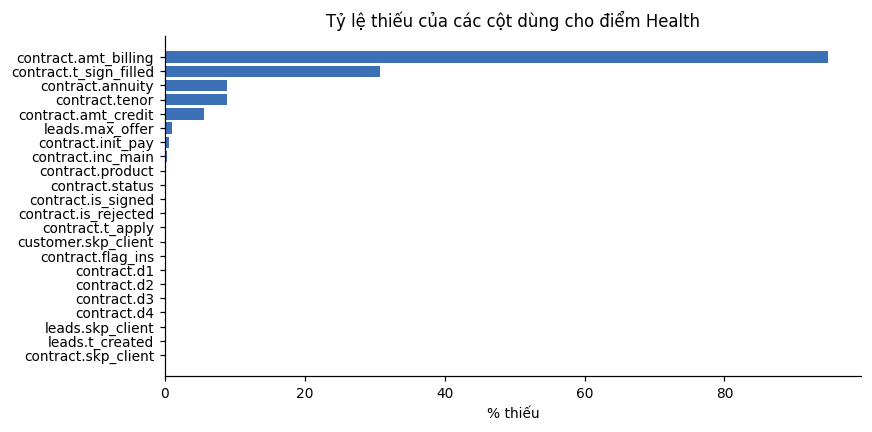

In [14]:
con = hp.load_and_check(cfg)
display(Markdown("**Kiểm tra bảng**"), pd.read_csv(cfg["out"] / "02_table_checks.csv"))
display(Markdown("**Kiểm tra logic CONTRACT**"), pd.read_csv(cfg["out"] / "02_logic_checks.csv", index_col=0))
miss = pd.read_csv(cfg["out"] / "02_column_missing.csv")
fig, ax = plt.subplots(figsize=(8, 4))
m = miss.sort_values("ty_le_thieu")
ax.barh(m.bang + "." + m.cot, m.ty_le_thieu * 100, color="#3b6fb6"); ax.set_xlabel("% thiếu")
ax.set_title("Tỷ lệ thiếu của các cột dùng cho điểm Health"); plt.tight_layout(); plt.show()

## Bước 3 · Snapshot khách hàng (`build_snapshot`)
Chỉ giữ dữ liệu có trước ngày chấm; mỗi khách một dòng. Hàm tự kiểm tra không có bản ghi nào sau mốc lọt vào, và gắn **mức độ đầy đủ dữ liệu** cho từng khách.

,so_khach,ty_trong
data_completeness,,
Đầy đủ (≥ 2 HĐ đã qua ≥ 3 kỳ trả),586299,0.5860
Một phần (1 HĐ đã qua ≥ 3 kỳ trả),227367,0.2272
Chưa đủ lịch sử trả nợ (chưa có HĐ nào qua ≥ 3 kỳ trả),186862,0.1868


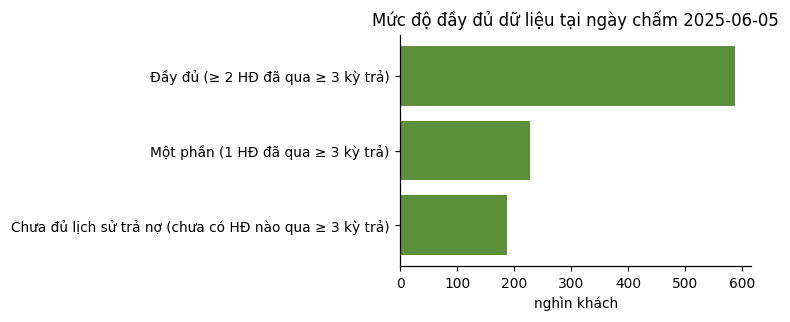

In [15]:
snap = hp.build_snapshot(con, cfg["score_date"])
comp = snap.data_completeness.value_counts()
display(comp.to_frame("so_khach").assign(ty_trong=lambda d: d.so_khach / d.so_khach.sum()))
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(comp.index[::-1], comp.values[::-1] / 1e3, color="#5b8f3a"); ax.set_xlabel("nghìn khách")
ax.set_title(f"Mức độ đầy đủ dữ liệu tại ngày chấm {cfg['score_date']}"); plt.tight_layout(); plt.show()

## Bước 4 · Tạo biến (`feature_engineering`)
Tạo biến cho 5 mốc huấn luyện và mốc kiểm chứng (lần đầu khoảng 1 phút/mốc, sau đó đọc từ cache).

,so_khach,ty_le_xau
cutoff,,
2024-02-01,58165,0.0104
2024-04-01,67183,0.0094
2024-06-01,65387,0.0106
2024-08-01,56761,0.0118
2024-10-01,40514,0.0317
2024-12-01,584057,0.0288


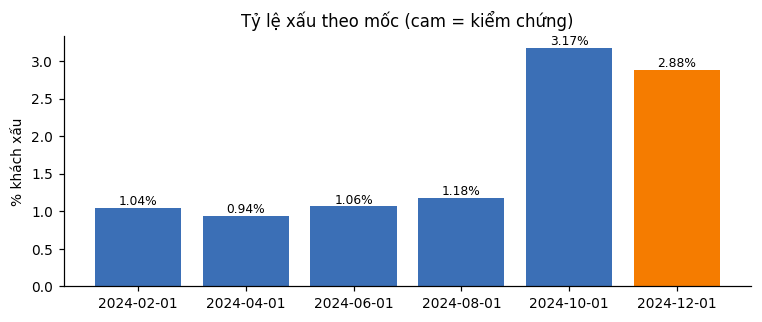

,skp_client,cutoff,income,inc_cv,n_income_values,inc_growth,inc_vs_peak,n_professions,n_income_types,income_years_declared,residual_income,n_active,n_active_revolving,n_active_products2
0,13313192,2024-02-01,"25,000,000.0000",0.2393,4,1.6667,1.0000,2,1,2.7023,"21,903,000.0000",2,0,2
1,14907668,2024-02-01,"18,000,000.0000",0.2955,4,1.8000,1.0000,1,1,2.7515,"14,372,000.0000",2,0,1
2,15160292,2024-02-01,"15,000,000.0000",0.0000,1,1.0000,1.0000,1,1,1.0349,"15,000,000.0000",0,0,0
3,71000914,2024-02-01,"5,000,000.0000",NaN,<NA>,NaN,NaN,<NA>,<NA>,NaN,"5,000,000.0000",0,0,0
4,72670447,2024-02-01,"15,000,000.0000",0.4442,4,1.2500,1.0000,2,2,2.8830,"11,330,000.0000",2,0,1


In [16]:
parts = [hp.feature_engineering(con, cfg, c) for c in cfg["dev_cutoffs"] + [cfg["oot_cutoff"]]]
data = pd.concat(parts, ignore_index=True)
by = data.groupby("cutoff").agg(so_khach=("bad", "size"), ty_le_xau=("bad", "mean"))
display(by)
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(by.index, by.ty_le_xau * 100, color=["#3b6fb6"] * 5 + ["#f57c00"])
for i, v in enumerate(by.ty_le_xau): ax.text(i, v * 100, f"{v:.2%}", ha="center", va="bottom", fontsize=8)
ax.set_ylabel("% khách xấu"); ax.set_title("Tỷ lệ xấu theo mốc (cam = kiểm chứng)"); plt.tight_layout(); plt.show()
display(data[["skp_client", "cutoff"] + list(cfg["variables"])[:12]].head())

## Bước 5 · Kiểm tra biến (`validate_features`)
Giá trị vô cực (mẫu số bằng 0) và giá trị bất hợp lý (tỷ lệ ngoài 0–1, số âm, thu nhập bằng 0) được đặt là **thiếu**. Cặp biến có |Spearman| > 0.95 được báo cáo; chỉ loại biến khi cả Spearman và Pearson > 0.99 (các biến đếm trễ hạn có ~97% giá trị 0 nên Spearman gần 1 dù mang thông tin khác nhau).

[  282s] Bước 5 – dev_oot: 0 giá trị vô cực, 23 giá trị bất hợp lý (đã đặt = thiếu); 12 cặp biến trùng thông tin (|ρ| > 0.95)


[  282s] 
              bien_1                bien_2  spearman  pearson  loai_bien_2
            n_active    n_active_products2    0.9890   0.9410        False
overdue_recency_code           n_due_total    1.0000   0.7930        False
overdue_recency_code          on_time_rate    1.0000   0.6390        False
overdue_recency_code       max_late_streak    1.0000   0.8060        False
         n_due_total          on_time_rate    1.0000   0.8120        False
         n_due_total       max_late_streak    1.0000   0.9640        False
        on_time_rate       max_late_streak    1.0000   0.8250        False
           n_on_time      n_clean_finished    0.9910   0.9930         True
           n_on_time              n_signed    0.9760   0.9860        False
    n_clean_finished              n_signed    0.9660   0.9790        False
               n_fpd              fpd_rate    1.0000   0.8040        False
          n_apply_6m n_products_applied_6m    0.9910   0.8780        False


[  282s] Độ đầy đủ lịch sử:
data_completeness
Đầy đủ (≥ 2 HĐ đã qua ≥ 3 kỳ trả)                        0.5240
Chưa đủ lịch sử trả nợ (chưa có HĐ nào qua ≥ 3 kỳ trả)   0.3000
Một phần (1 HĐ đã qua ≥ 3 kỳ trả)                        0.1760


,bien,nhom,co_du_lieu,vo_cuc,bat_hop_ly
53,history_years,6. Áp lực vay & độ tin cậy,0.7168,0,23


**Cặp biến trùng thông tin**

,bien_1,bien_2,spearman,pearson,loai_bien_2
0,n_active,n_active_products2,0.9894,0.9405,False
1,overdue_recency_code,n_due_total,0.9997,0.7932,False
2,overdue_recency_code,on_time_rate,0.9997,0.6388,False
3,overdue_recency_code,max_late_streak,0.9997,0.8056,False
4,n_due_total,on_time_rate,0.9998,0.8119,False
5,n_due_total,max_late_streak,1.0000,0.9642,False
6,on_time_rate,max_late_streak,0.9998,0.8246,False
7,n_on_time,n_clean_finished,0.9908,0.9926,True
8,n_on_time,n_signed,0.9764,0.9860,False
9,n_clean_finished,n_signed,0.9661,0.9789,False


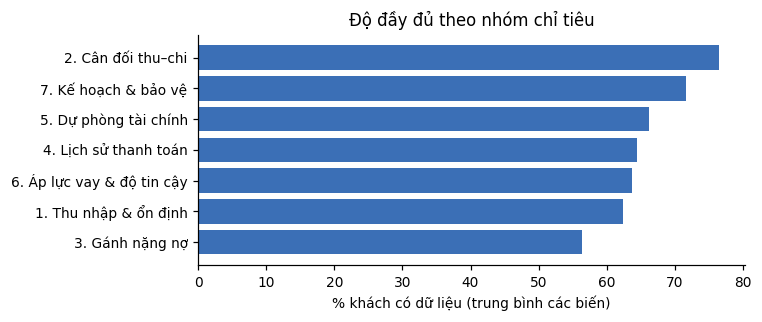

11401

In [17]:
data, dup = hp.validate_features(data, cfg, "dev_oot")
q = pd.read_csv(cfg["out"] / "05_feature_quality_dev_oot.csv")
display(q[(q.vo_cuc > 0) | (q.bat_hop_ly > 0)][["bien", "nhom", "co_du_lieu", "vo_cuc", "bat_hop_ly"]])
display(Markdown("**Cặp biến trùng thông tin**"), dup)
fig, ax = plt.subplots(figsize=(7, 3))
cov = q.groupby("nhom").co_du_lieu.mean().sort_values()
ax.barh(cov.index, cov * 100, color="#3b6fb6"); ax.set_xlabel("% khách có dữ liệu (trung bình các biến)")
ax.set_title("Độ đầy đủ theo nhóm chỉ tiêu"); plt.tight_layout(); plt.show()
dev = data[data.cutoff.isin(cfg["dev_cutoffs"])].reset_index(drop=True)
oot = data[data.cutoff == cfg["oot_cutoff"]].reset_index(drop=True)
import gc; del parts, data, snap; gc.collect()   # giải phóng bộ nhớ (máy 16GB)

### 1.4 Phân tích từng chỉ tiêu: có tách được khách tốt / xấu không?
Trên tập huấn luyện: AUC đơn biến (0,5 = không phân biệt được), chiều thực tế (giá trị cao đi cùng rủi ro cao hay thấp), tỷ lệ xấu khi thiếu dữ liệu, và tỷ lệ xấu theo nhóm giá trị.

Nhóm,Chỉ_tiêu,Mã,Có_dữ_liệu,AUC_đơn_biến,Chiều_thực_tế,Xấu_khi_thiếu
4. Lịch sử thanh toán,Số HĐ tất toán không trễ kỳ nào,n_clean_finished,85.3%,0.615,cao → an toàn hơn,1.99%
4. Lịch sử thanh toán,Số kỳ trả đúng hạn,n_on_time,85.3%,0.610,cao → an toàn hơn,1.99%
6. Áp lực vay & độ tin cậy,Số HĐ đã ký,n_signed,85.3%,0.602,cao → an toàn hơn,1.99%
5. Dự phòng tài chính,Tỷ lệ trả trước (CD/TW),down_payment_ratio,79.2%,0.567,cao → an toàn hơn,2.10%
6. Áp lực vay & độ tin cậy,Tỷ lệ hồ sơ bị từ chối,refused_ratio,85.3%,0.560,cao → rủi ro hơn,1.99%
6. Áp lực vay & độ tin cậy,Hồ sơ gần nhất bị từ chối,last_app_rejected,85.3%,0.558,cao → rủi ro hơn,1.99%
1. Thu nhập & ổn định,Số nghề nghiệp đã khai,n_professions,75.1%,0.555,cao → an toàn hơn,1.80%
5. Dự phòng tài chính,Tiền trả trước trung bình,avg_init_pay,79.2%,0.554,cao → an toàn hơn,2.10%
6. Áp lực vay & độ tin cậy,Hạn mức công ty sẵn sàng cấp (gần nhất),max_offer,43.6%,0.554,cao → an toàn hơn,1.79%
3. Gánh nặng nợ,Số HĐ đang hoạt động,n_active,85.3%,0.549,cao → an toàn hơn,1.99%


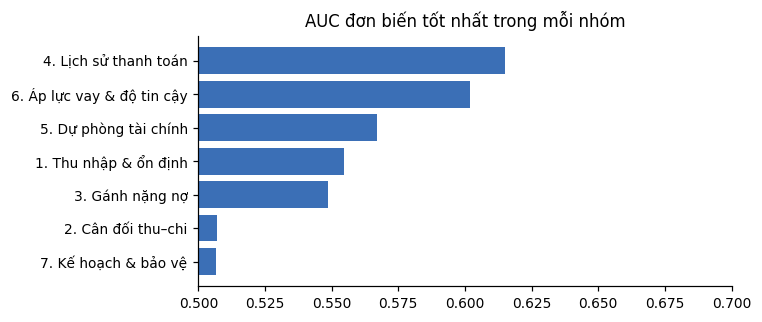

In [18]:
from sklearn.metrics import roc_auc_score
rows = []
for v in cfg["variables"]:
    x = dev[v].astype(float)
    if x.notna().sum() < 1000 or x.nunique() < 2:
        continue
    a = roc_auc_score(dev.bad, x.fillna(x.median()))
    rows.append(dict(Nhóm=cfg["variables"][v][0], Chỉ_tiêu=cfg["variables"][v][1], Mã=v, Có_dữ_liệu=x.notna().mean(),
                     AUC_đơn_biến=max(a, 1 - a), Chiều_thực_tế="cao → rủi ro hơn" if a > .5 else "cao → an toàn hơn",
                     Xấu_khi_thiếu=dev.bad[x.isna()].mean() if x.isna().any() else np.nan))
uni = pd.DataFrame(rows).sort_values("AUC_đơn_biến", ascending=False)
display(uni.head(25).style.hide(axis="index").format({"Có_dữ_liệu": "{:.1%}", "AUC_đơn_biến": "{:.3f}", "Xấu_khi_thiếu": "{:.2%}"}))
gbest = uni.groupby("Nhóm").AUC_đơn_biến.max().sort_values()
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(gbest.index, gbest, color="#3b6fb6"); ax.set_xlim(.5, max(.7, gbest.max() + .02))
ax.set_title("AUC đơn biến tốt nhất trong mỗi nhóm"); plt.tight_layout(); plt.show()

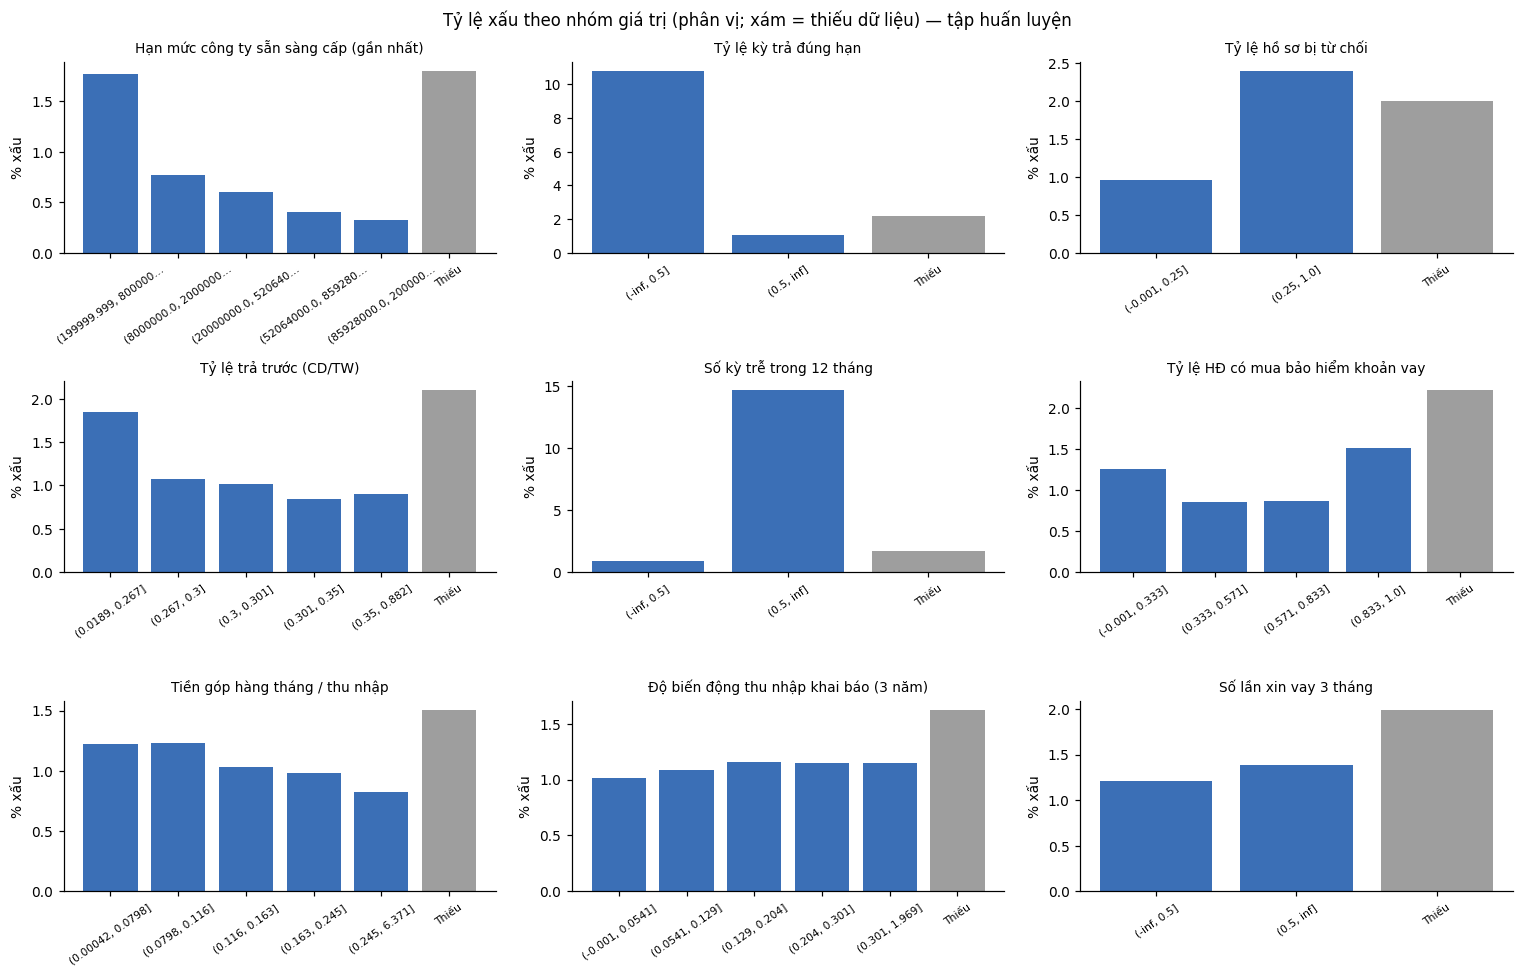

In [19]:
key = ["max_offer", "on_time_rate", "refused_ratio", "down_payment_ratio", "n_inst_late_12m", "pct_insured2",
       "active_annuity_income", "inc_cv", "n_apply_3m"]
fig, axes = plt.subplots(3, 3, figsize=(14, 9))
for ax, v in zip(axes.ravel(), key):
    x = dev[v].astype(float)
    q = np.unique(np.nanquantile(x, [0, .2, .4, .6, .8, 1]))
    b = pd.cut(x, q, include_lowest=True, duplicates="drop") if len(q) > 2 else pd.cut(x, [-np.inf, 0.5, np.inf])
    lab = b.cat.categories.astype(str).tolist()
    t = dev.groupby(b, observed=False).bad.mean().tolist() + ([dev.bad[x.isna()].mean()] if x.isna().any() else [])
    lab += ["Thiếu"] if x.isna().any() else []
    ax.bar(range(len(t)), np.array(t) * 100, color=["#9e9e9e" if l == "Thiếu" else "#3b6fb6" for l in lab])
    ax.set_xticks(range(len(t))); ax.set_xticklabels([l if len(l) < 20 else l[:19] + "…" for l in lab], rotation=35, fontsize=7)
    ax.set_title(cfg["variables"][v][1], fontsize=9); ax.set_ylabel("% xấu")
plt.suptitle("Tỷ lệ xấu theo nhóm giá trị (phân vị; xám = thiếu dữ liệu) — tập huấn luyện"); plt.tight_layout(); plt.show()

# Câu 2 · Customer Financial Health Score 0–100
**Vì sao Gradient Boosting + SHAP?** Trên cùng tập kiểm chứng, scorecard WoE truyền thống đạt AUC 0,661; Gradient Boosting cao hơn vì học được quan hệ phi tuyến và tương tác giữa các chỉ tiêu (ví dụ: bị từ chối nhiều chỉ đáng lo khi hạn mức thấp).
Để vẫn giải thích được như scorecard: (1) ràng buộc đơn điệu cho các biến có chiều nghiệp vụ rõ; (2) SHAP tách điểm thành điểm cộng/trừ của từng chỉ tiêu.

## Huấn luyện mô hình
1. Huấn luyện trên 4 mốc đầu, dừng sớm theo AUC mốc 10/2024.
2. Bỏ biến đóng góp dưới 0,5% tổng |SHAP| (đo trên mốc 10/2024, không đụng tập kiểm chứng).
3. Fit lại trên cả 5 mốc với số cây đã chọn.

In [20]:
M = hp.fit_model(cfg, dev, dup)
sel = VARS.set_index("bien").loc[M["feats"]].reset_index()
display(sel.groupby("nhom").bien.apply(lambda x: ", ".join(x)).to_frame("bien_duoc_giu"))

[  363s] Chọn biến: 55 → 37 biến (SHAP ≥ 0.5%); AUC mốc 2024-10-01 0.7199; 170 cây


,bien_duoc_giu
nhom,
1. Thu nhập & ổn định,"inc_cv, income_years_declared, n_income_types,..."
2. Cân đối thu–chi,residual_income
3. Gánh nặng nợ,"n_active_revolving, active_credit_income, acti..."
4. Lịch sử thanh toán,"n_on_time, on_time_rate, n_inst_late_12m, n_in..."
5. Dự phòng tài chính,"max_init_pay_24m, init_pay_income, down_paymen..."
6. Áp lực vay & độ tin cậy,"max_offer, last_app_rejected, refused_ratio, o..."
7. Kế hoạch & bảo vệ,pct_insured2


## Bước 6 · Chấm từng chỉ tiêu (`score_features`)
Điểm chỉ tiêu 0–100 = vị trí đóng góp SHAP của chỉ tiêu đó, nằm giữa mức tệ nhất (phân vị 1%) và tốt nhất (phân vị 99%) trên tập huấn luyện.
**100** = chỉ tiêu đang giúp khách nhiều nhất, **0** = đang kéo điểm xuống nhiều nhất.

**Quy tắc thiếu dữ liệu:** LightGBM học một nhánh riêng cho giá trị thiếu, nên khách thiếu một chỉ tiêu nhận đúng mức rủi ro quan sát được của nhóm khách cũng thiếu chỉ tiêu đó (thường là khách chưa có lịch sử, nên bị trừ điểm nhẹ). Cột `miss_<biến>` đánh dấu để báo cáo.

In [21]:
S_dev, b_dev, pts_dev, miss_dev, rng_f = hp.score_features(M, cfg, dev)
S_oot, b_oot, pts_oot, miss_oot, _ = hp.score_features(M, cfg, oot, rng_f)
ex = pts_oot.sample(5, random_state=1).round(0)
ex.columns = [cfg["variables"][c][1] for c in ex.columns]
display(Markdown("**Điểm chỉ tiêu của 5 khách ngẫu nhiên (tập kiểm chứng)**"), ex.T.head(15))
del pts_dev, miss_dev, pts_oot, miss_oot; gc.collect()

**Điểm chỉ tiêu của 5 khách ngẫu nhiên (tập kiểm chứng)**

,545925,420364,100877,218187,331424
Hạn mức công ty sẵn sàng cấp (gần nhất),20.0000,56.0000,59.0000,72.0000,16.0000
Số kỳ trả đúng hạn,8.0000,7.0000,93.0000,0.0000,7.0000
Hồ sơ gần nhất bị từ chối,93.0000,23.0000,91.0000,91.0000,95.0000
Tiền trả trước lớn nhất 24 tháng,20.0000,15.0000,27.0000,18.0000,10.0000
Tiền trả trước / thu nhập,71.0000,64.0000,83.0000,55.0000,0.0000
Tỷ lệ trả trước (CD/TW),63.0000,61.0000,76.0000,59.0000,52.0000
Tỷ lệ hồ sơ bị từ chối,57.0000,17.0000,84.0000,75.0000,67.0000
Số HĐ quay vòng (thẻ/hạn mức) đang mở,3.0000,3.0000,91.0000,2.0000,3.0000
Hạn mức hiện tại / 6 tháng trước,22.0000,20.0000,45.0000,42.0000,16.0000
Số năm có lịch sử vay,36.0000,23.0000,60.0000,76.0000,44.0000


15947

## Bước 7 · Tổng hợp điểm (`aggregate_scores`)
**Financial Health Score = 50 + 15/ln2 × (log-odds tốt − log-odds tốt trung bình của tập huấn luyện)**, cắt về 0–100.
50 điểm = mức rủi ro trung bình; mỗi +15 điểm = odds tốt/xấu gấp đôi.
Vì SHAP cộng tính: **điểm = điểm gốc + Σ điểm cộng/trừ của từng nhóm** (cột `diem_cong_tru_nhom_*`). Điểm nhóm 0–100 tính như điểm chỉ tiêu nhưng trên tổng SHAP của nhóm.

**Không đủ dữ liệu:** khách chưa có khoản vay nào (trả góp, BNPL hoặc thẻ) qua **≥ 3 kỳ trả** vẫn có điểm nhưng được xếp hạng **N · Chưa đủ lịch sử trả nợ**, gồm cả khách chưa từng vay và khách có khoản vay chưa đến kỳ trả. Nhóm được định nghĩa theo **bằng chứng trả nợ**, không theo loại sản phẩm: thiếu bằng chứng thì không xếp hạng khỏe.

,skp_client,financial_health_score,diem_nhom_1,diem_cong_tru_nhom_1,diem_nhom_2,diem_cong_tru_nhom_2,diem_nhom_3,diem_cong_tru_nhom_3,diem_nhom_4,diem_cong_tru_nhom_4,diem_nhom_5,diem_cong_tru_nhom_5,diem_nhom_6,diem_cong_tru_nhom_6,diem_nhom_7,diem_cong_tru_nhom_7,xac_suat_xau,health_band,band_name,data_completeness
0,82318857,78.7000,83.6000,1.1800,41.5000,0.0700,17.2000,-0.1600,81.6000,2.3100,60.7000,-1.1300,87.7000,18.9500,74.8000,0.4900,0.0036,A,A · Rất khỏe,Đầy đủ (≥ 2 HĐ đã qua ≥ 3 kỳ trả)
1,82353638,56.6000,23.9000,-3.7800,28.9000,-0.4400,12.7000,-0.7200,76.7000,0.7100,65.4000,-0.0800,57.9000,3.4800,73.0000,0.4200,0.0100,C,C · Trung bình,Đầy đủ (≥ 2 HĐ đã qua ≥ 3 kỳ trả)
2,82355568,69.3000,76.7000,0.6000,37.8000,-0.0800,16.5000,-0.2500,77.1000,0.8600,71.0000,1.1600,69.9000,9.7100,69.4000,0.2800,0.0056,A,A · Rất khỏe,Đầy đủ (≥ 2 HĐ đã qua ≥ 3 kỳ trả)
3,82413151,75.9000,0.0000,-5.9100,66.2000,1.0700,21.9000,0.4300,85.9000,3.7100,63.3000,-0.5400,89.6000,19.9400,67.2000,0.1900,0.0041,A,A · Rất khỏe,Đầy đủ (≥ 2 HĐ đã qua ≥ 3 kỳ trả)
4,82413658,67.1000,31.8000,-3.1300,31.2000,-0.3500,15.6000,-0.3600,86.7000,3.9600,68.0000,0.4900,69.4000,9.4500,63.7000,0.0400,0.0062,A,A · Rất khỏe,Đầy đủ (≥ 2 HĐ đã qua ≥ 3 kỳ trả)


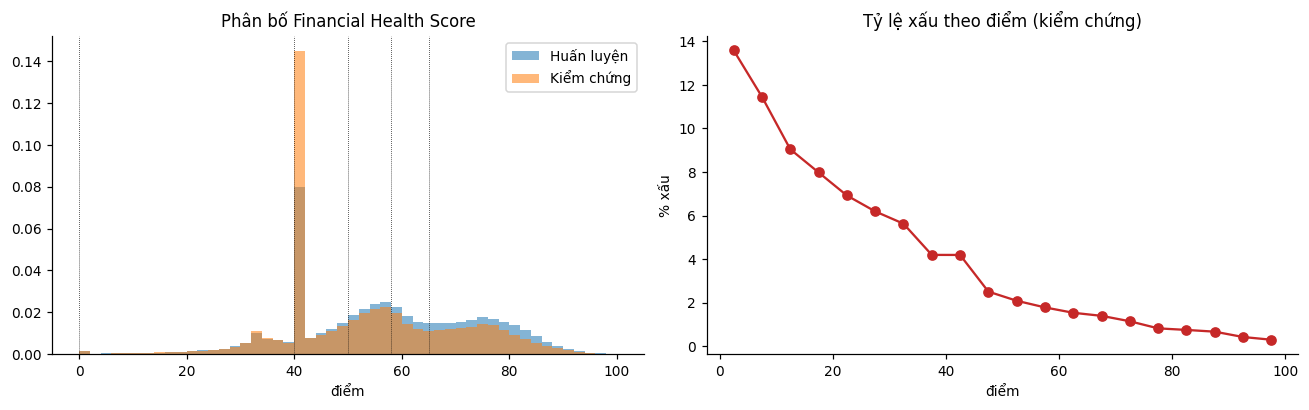

In [22]:
sc_dev, rng_g = hp.aggregate_scores(M, cfg, dev, S_dev, b_dev)
sc_oot, _ = hp.aggregate_scores(M, cfg, oot, S_oot, b_oot, rng_g)
display(sc_oot.head())
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
bins = np.arange(0, 101, 2)
for d, lab in [(sc_dev, "Huấn luyện"), (sc_oot, "Kiểm chứng")]:
    axes[0].hist(d.financial_health_score, bins=bins, alpha=.55, density=True, label=lab)
for lo, hi, b in cfg["bands"]:
    axes[0].axvline(lo, color="k", lw=.5, ls=":")
axes[0].legend(); axes[0].set_title("Phân bố Financial Health Score"); axes[0].set_xlabel("điểm")
o = sc_oot.assign(bad=oot.bad.values, bin=pd.cut(sc_oot.financial_health_score, np.arange(0, 101, 5)))
r = o.groupby("bin", observed=True).bad.mean()
axes[1].plot([i.mid for i in r.index], r.values * 100, "o-", color="#c62828")
axes[1].set_title("Tỷ lệ xấu theo điểm (kiểm chứng)"); axes[1].set_xlabel("điểm"); axes[1].set_ylabel("% xấu")
plt.tight_layout(); plt.show()

### Chấm điểm toàn bộ khách tại ngày chấm

,count,mean,std,min,25%,50%,75%,max
điểm,"1,000,528.0000",51.8775,21.3684,0.0000,33.6000,53.5000,68.8000,100.0000


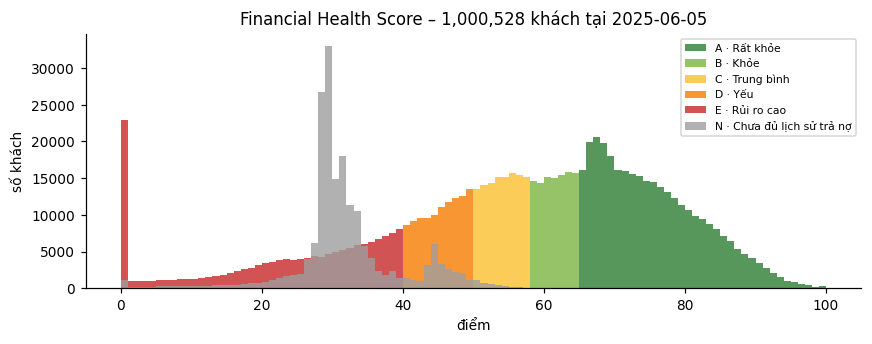

In [23]:
final = hp.feature_engineering(con, cfg, cfg["score_date"], with_label=False)
final, _ = hp.validate_features(final, cfg, "score_date", report=False)
S_f, b_f, pts_f, miss_f, _ = hp.score_features(M, cfg, final, rng_f)
sc_f, _ = hp.aggregate_scores(M, cfg, final, S_f, b_f, rng_g)
display(sc_f.financial_health_score.describe().to_frame("điểm").T)
fig, ax = plt.subplots(figsize=(8, 3.2))
for b, t in sc_f.groupby("health_band"):
    ax.hist(t.financial_health_score, bins=np.arange(0, 101, 1), color=BAND_COLORS[b], alpha=.8, label=cfg["band_name"][b])
ax.legend(fontsize=7); ax.set_xlabel("điểm"); ax.set_ylabel("số khách"); ax.set_title(f"Financial Health Score – {len(sc_f):,} khách tại {cfg['score_date']}")
plt.tight_layout(); plt.show()

# Câu 3 · Phân nhóm khách hàng
Ngưỡng hạng được chọn sao cho tỷ lệ xấu tăng rõ rệt giữa các hạng và mỗi hạng đủ lớn để có chính sách riêng. Khách chưa có khoản vay nào qua ≥ 3 kỳ trả được tách riêng thành **N · Chưa đủ lịch sử trả nợ** (điểm dựa trên rất ít bằng chứng; chính sách: hạn mức nhỏ BNPL/CD, tăng dần sau mỗi kỳ trả đúng hạn).

In [24]:
seg = pd.DataFrame([(b, cfg["band_name"][b], f"{lo}–{hi if hi < 101 else 100}", cfg["band_action"][b]) for lo, hi, b in cfg["bands"][::-1]]
                   + [("N", cfg["band_name"]["N"], "chưa có khoản vay nào qua ≥ 3 kỳ trả", cfg["band_action"]["N"])],
                   columns=["hạng", "tên", "khoảng điểm", "hành động gợi ý"]).set_index("hạng")
o = sc_oot.assign(bad=oot.bad.values)
seg["tỷ lệ xấu (kiểm chứng)"] = o.groupby("health_band").bad.mean()
seg["tỷ trọng (kiểm chứng)"] = o.health_band.value_counts(normalize=True)
seg["số khách hiện tại"] = sc_f.health_band.value_counts()
seg["tỷ trọng hiện tại"] = sc_f.health_band.value_counts(normalize=True)
display(seg.style.format({"tỷ lệ xấu (kiểm chứng)": "{:.2%}", "tỷ trọng (kiểm chứng)": "{:.1%}", "tỷ trọng hiện tại": "{:.1%}",
                          "số khách hiện tại": "{:,.0f}"}).set_properties(**{"text-align": "left"}))

,tên,khoảng điểm,hành động gợi ý,tỷ lệ xấu (kiểm chứng),tỷ trọng (kiểm chứng),số khách hiện tại,tỷ trọng hiện tại
hạng,,,,,,,
A,A · Rất khỏe,65–100,"Ưu tiên tăng hạn mức, mời sản phẩm giá trị cao (CL, thẻ), duyệt nhanh",1.01%,25.4%,"324,326",32.4%
B,B · Khỏe,58–65,"Duy trì, bán thêm có chọn lọc với hạn mức hiện tại",1.57%,10.2%,"106,002",10.6%
C,C · Trung bình,50–58,"Cho vay có kiểm soát: sản phẩm có trả trước (CD, TW), hạn mức vừa phải",1.99%,15.7%,"118,628",11.9%
D,D · Yếu,40–50,"Hạn chế cấp mới, chỉ khoản nhỏ có trả trước; theo dõi sát",2.73%,8.3%,"108,038",10.8%
E,E · Rủi ro cao,0–40,"Không cấp tín dụng mới; ưu tiên nhắc nợ, tư vấn tài chính",6.09%,6.1%,"156,672",15.7%
N,N · Chưa đủ lịch sử trả nợ,chưa có khoản vay nào qua ≥ 3 kỳ trả,"Hạn mức nhỏ (BNPL/CD), tăng dần hạn mức sau mỗi kỳ trả đúng hạn; chưa xếp hạng khỏe khi chưa có bằng chứng trả nợ",4.54%,34.3%,"186,862",18.7%


**Chân dung từng hạng** (trung vị chỉ tiêu, khách hiện tại) — giúp đặt tên và chính sách cho từng nhóm.

band,A,B,C,D,E,N
% có HĐ trễ,0.01,0.01,0.02,0.03,0.27,0.00
Thu nhập chính khai báo,"12,000,000.00","12,000,000.00","11,000,000.00","11,000,000.00","11,000,000.00","10,000,000.00"
Hạn mức công ty sẵn sàng cấp (gần nhất),"43,979,000.00","8,941,000.00","3,000,000.00","2,000,000.00","2,000,000.00","8,000,000.00"
Tỷ lệ kỳ trả đúng hạn,1.00,1.00,1.00,1.00,1.00,nan
Tổng số kỳ trễ hạn,0.00,0.00,0.00,0.00,0.00,nan
Tỷ lệ hồ sơ bị từ chối,0.00,0.00,0.00,0.00,0.31,1.00
Số lần xin vay 6 tháng,1.00,1.00,1.00,1.00,1.00,1.00
Số HĐ đang hoạt động,1.00,1.00,1.00,1.00,0.00,0.00
Tiền góp hàng tháng / thu nhập,0.14,0.14,0.14,0.12,0.11,0.10
Tỷ lệ trả trước (CD/TW),0.30,0.30,0.30,0.30,0.23,0.28


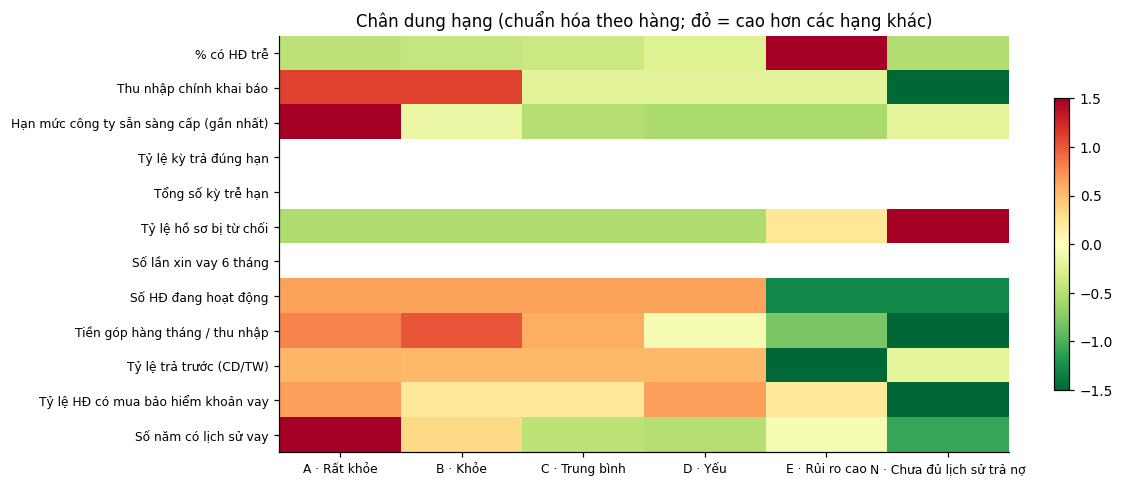

In [25]:
prof_vars = ["income", "max_offer", "on_time_rate", "n_due_total", "refused_ratio", "n_apply_6m", "n_active",
             "active_annuity_income", "down_payment_ratio", "pct_insured2", "history_years"]
pf = final.assign(band=sc_f.health_band.values)
prof = pf.groupby("band")[prof_vars].median().reindex(list("ABCDEN"))
prof.insert(0, "late", pf.assign(late=pf.n_due_total.fillna(0) > 0).groupby("band").late.mean())
prof.columns = ["% có HĐ trễ"] + [cfg["variables"][v][1] for v in prof_vars]
display(prof.T.style.format("{:,.2f}"))
z = (prof - prof.mean()) / prof.std()
fig, ax = plt.subplots(figsize=(11, 4.5))
im = ax.imshow(z.T.values, cmap="RdYlGn_r", aspect="auto", vmin=-1.5, vmax=1.5)
ax.set_xticks(range(len(z.index))); ax.set_xticklabels([cfg["band_name"][b] for b in z.index], fontsize=8)
ax.set_yticks(range(len(z.columns))); ax.set_yticklabels(z.columns, fontsize=8)
ax.set_title("Chân dung hạng (chuẩn hóa theo hàng; đỏ = cao hơn các hạng khác)"); plt.colorbar(im, ax=ax, shrink=.7)
plt.tight_layout(); plt.show()

# Câu 4 · Yếu tố tác động tích cực / tiêu cực đến sức khỏe tài chính
### 4.1 Relative risk từ dữ liệu (độc lập với mô hình)
RR = tỷ lệ xấu của nhóm *có* yếu tố ÷ tỷ lệ xấu của nhóm *không có*, tính trên đúng quần thể huấn luyện (chỉ tiêu tại mốc, nhãn sau mốc). RR > 1 làm **xấu** sức khỏe tài chính, RR < 1 làm **tốt**. Kết quả này sau đó được đối chiếu với SHAP của mô hình (4.2).

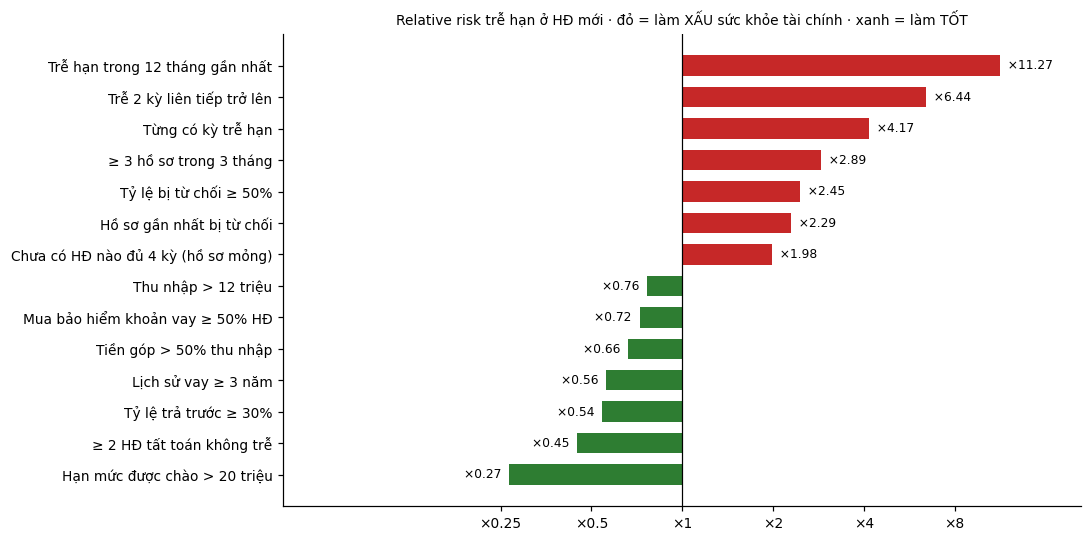

,so_kh,ty_trong,xau_khi_co,xau_khi_khong,RR
yeu_to,,,,,
Hạn mức được chào > 20 triệu,"75,014",26.0%,0.44%,1.67%,0.27
≥ 2 HĐ tất toán không trễ,"173,378",60.2%,0.91%,2.02%,0.45
Tỷ lệ trả trước ≥ 30%,"156,542",54.4%,0.98%,1.80%,0.54
Lịch sử vay ≥ 3 năm,"155,579",54.0%,0.99%,1.77%,0.56
Tiền góp > 50% thu nhập,"2,007",0.7%,0.90%,1.35%,0.66
Mua bảo hiểm khoản vay ≥ 50% HĐ,"126,758",44.0%,1.11%,1.54%,0.72
Thu nhập > 12 triệu,"75,910",26.4%,1.10%,1.44%,0.76
Chưa có HĐ nào đủ 4 kỳ (hồ sơ mỏng),"62,650",21.8%,2.20%,1.11%,1.98
Hồ sơ gần nhất bị từ chối,"33,144",11.5%,2.69%,1.18%,2.29


In [26]:
rr = eda_reasoning.relative_risk(dev)
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(rr.index, np.log2(rr.RR), color=["#c62828" if v > 1 else "#2e7d32" for v in rr.RR], height=.65)
for i, v in enumerate(rr.RR):
    ax.text(np.log2(v), i, f"  ×{v:.2f}" if v > 1 else f"×{v:.2f}  ", va="center", ha="left" if v > 1 else "right", fontsize=8)
ax.axvline(0, color="k", lw=.8)
ticks = [.25, .5, 1, 2, 4, 8]
ax.set_xticks(np.log2(ticks)); ax.set_xticklabels([f"×{t:g}" for t in ticks])
lim = np.abs(np.log2(rr.RR)).max() + .9; ax.set_xlim(-lim, lim)
ax.set_title("Relative risk trễ hạn ở HĐ mới · đỏ = làm XẤU sức khỏe tài chính · xanh = làm TỐT", fontsize=9)
plt.tight_layout(); plt.show()
display(rr.style.format({"so_kh": "{:,.0f}", "ty_trong": "{:.1%}", "xau_khi_co": "{:.2%}", "xau_khi_khong": "{:.2%}", "RR": "{:.2f}"}))

> **Nhận xét – yếu tố tích cực / tiêu cực theo relative risk**
> - **Làm XẤU (RR > 1):** trễ hạn trong 12 tháng gần nhất **×11,9**; trễ 2 kỳ liên tiếp ×6,7; từng có kỳ trễ ×4,3; ≥ 3 hồ sơ trong 3 tháng ×2,9; bị từ chối ≥ 50% hồ sơ ×2,5; hồ sơ gần nhất bị từ chối ×2,3; hồ sơ mỏng ×2,0.
> - **Làm TỐT (RR < 1):** hạn mức được chào > 20 triệu **×0,27**; ≥ 2 HĐ tất toán không trễ ×0,45; trả trước ≥ 30% ×0,54; lịch sử vay ≥ 3 năm ×0,56; mua bảo hiểm ≥ 50% HĐ ×0,72; thu nhập > 12 triệu ×0,76.
> - **Cách đọc:** tín hiệu tiêu cực mạnh nhất đều là **hành vi trả nợ đã xảy ra** và **bị bên cho vay từ chối**; tín hiệu tích cực mạnh nhất là **đánh giá tốt của bên cho vay** và **lịch sử tín dụng tốt đã được chứng minh**. "Tiền góp > 50% thu nhập" có RR 0,66 chủ yếu do **chọn lọc** (khách được duyệt vay nhiều là khách được đánh giá tốt), không nên diễn giải theo nghĩa nhân quả.
> - Các chiều này **trùng khớp** với chiều tác động trong SHAP bên dưới: hai phương pháp độc lập cho cùng kết luận.

### 4.2 Giải thích toàn cục bằng SHAP (mô hình)
- **Mức quan trọng:** trung bình |SHAP| của từng biến.
- **Trọng số thực tế của nhóm:** tỷ trọng |SHAP| cộng theo nhóm (thay cho trọng số gán tay).
- **Beeswarm:** mỗi chấm là một khách; trục x > 0 là tăng xác suất xấu (giảm điểm); màu đỏ là giá trị biến cao.
- **Dependence:** cách điểm thay đổi theo giá trị của biến.

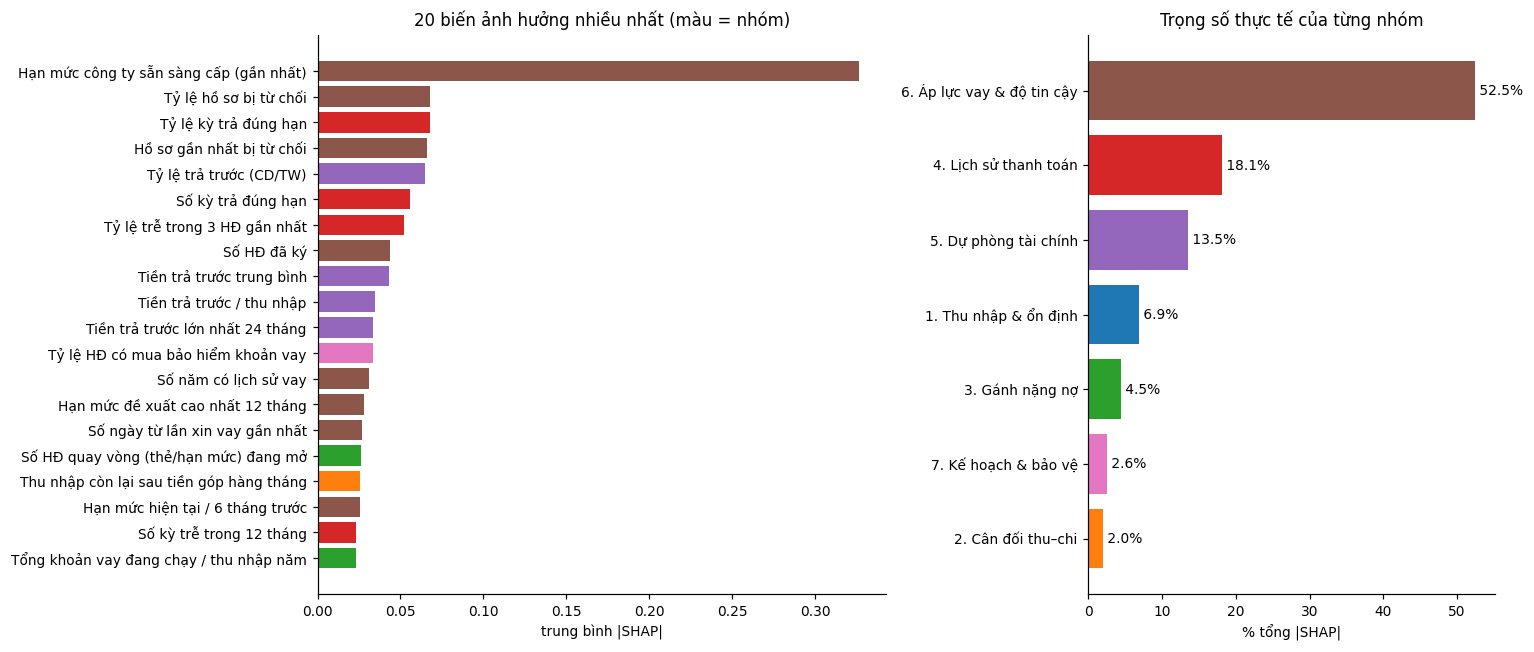

In [27]:
desc = {f: cfg["variables"][f][1] for f in M["feats"]}
G = pd.Series({f: cfg["variables"][f][0] for f in M["feats"]})
imp = S_oot.abs().mean().sort_values(ascending=False)
gi = imp.groupby(G).sum().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1.4, 1]})
top = imp.index[:20][::-1]
axes[0].barh([desc[f] for f in top], imp[top], color=[plt.cm.tab10(sorted(G.unique()).index(G[f])) for f in top])
axes[0].set_title("20 biến ảnh hưởng nhiều nhất (màu = nhóm)"); axes[0].set_xlabel("trung bình |SHAP|")
axes[1].barh(gi.index, gi / gi.sum() * 100, color=[plt.cm.tab10(sorted(G.unique()).index(g)) for g in gi.index])
for i, v in enumerate(gi / gi.sum() * 100): axes[1].text(v, i, f" {v:.1f}%", va="center")
axes[1].set_title("Trọng số thực tế của từng nhóm"); axes[1].set_xlabel("% tổng |SHAP|")
plt.tight_layout(); plt.show()

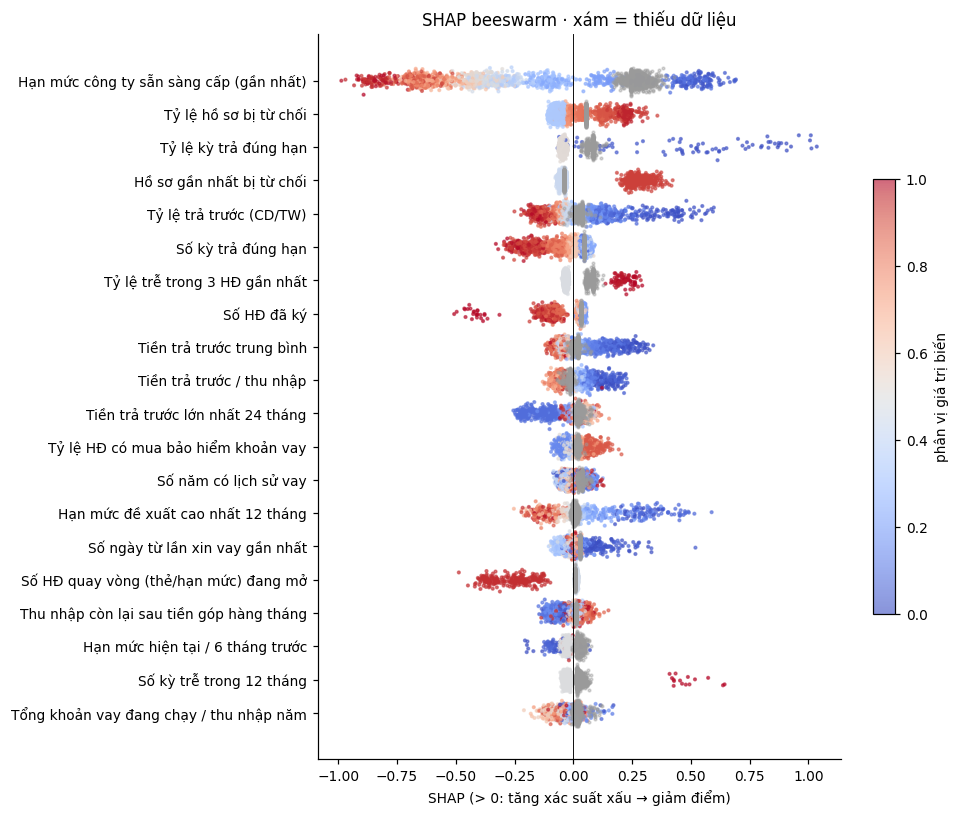

In [28]:
X = oot[M["feats"]].astype(float)
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(9, 7.5))
for i, f in enumerate(top):
    idx = rng.choice(len(X), 4000, replace=False)
    col = X[f].rank(pct=True).fillna(-1).values[idx]; s = S_oot[f].values[idx]; m = col < 0
    sc = ax.scatter(s[~m], i + rng.normal(0, .12, (~m).sum()), c=col[~m], cmap="coolwarm", s=3, alpha=.6, vmin=0, vmax=1)
    ax.scatter(s[m], i + rng.normal(0, .12, m.sum()), c="#9a9a9a", s=3, alpha=.4)
ax.set_yticks(range(len(top))); ax.set_yticklabels([desc[f] for f in top]); ax.axvline(0, color="k", lw=.6)
plt.colorbar(sc, ax=ax, label="phân vị giá trị biến", shrink=.6)
ax.set_xlabel("SHAP (> 0: tăng xác suất xấu → giảm điểm)"); ax.set_title("SHAP beeswarm · xám = thiếu dữ liệu")
plt.tight_layout(); plt.show()

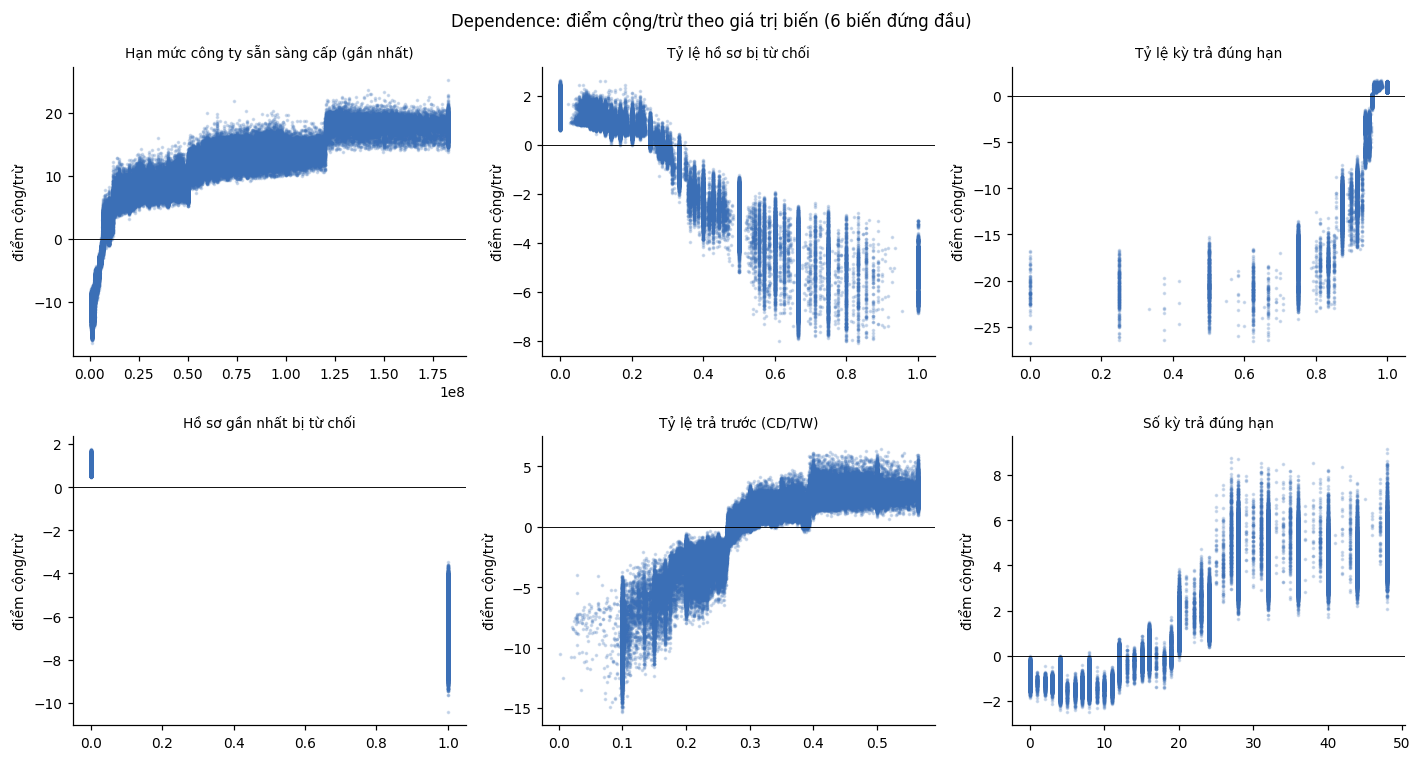

In [29]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, f in zip(axes.ravel(), imp.index[:6]):
    ok = X[f].notna()
    ax.scatter(X.loc[ok, f].clip(upper=X.loc[ok, f].quantile(.99)), -M["factor"] * S_oot.loc[ok, f], s=2, alpha=.2, color="#3b6fb6")
    ax.axhline(0, color="k", lw=.6); ax.set_title(desc[f], fontsize=9); ax.set_ylabel("điểm cộng/trừ")
plt.suptitle("Dependence: điểm cộng/trừ theo giá trị biến (6 biến đứng đầu)"); plt.tight_layout(); plt.show()

**Tổng hợp yếu tố tích cực / tiêu cực:** chiều = tương quan hạng giữa giá trị chỉ tiêu và điểm cộng/trừ; mức tác động = trung bình |điểm cộng/trừ|.

In [30]:
rows = []
for f in imp.index:
    ok = X[f].notna()
    r = np.corrcoef(X.loc[ok, f].rank(), -S_oot.loc[ok, f])[0, 1] if ok.sum() > 100 else np.nan
    pts = -M["factor"] * S_oot[f]
    rows.append(dict(Nhóm=G[f], Chỉ_tiêu=desc[f], Tác_động_TB_điểm=(M["factor"] * S_oot[f].abs()).mean(),
                     Chiều=("Tích cực: càng cao càng khỏe" if r > .1 else "Tiêu cực: càng cao càng yếu" if r < -.1 else "Phi tuyến / phụ thuộc ngữ cảnh"),
                     Điểm_cộng_tối_đa=pts.quantile(.99), Điểm_trừ_tối_đa=pts.quantile(.01)))
pn = pd.DataFrame(rows)
display(pn.head(20).style.hide(axis="index").format({"Tác_động_TB_điểm": "{:.2f}", "Điểm_cộng_tối_đa": "{:+.1f}", "Điểm_trừ_tối_đa": "{:+.1f}"}))

Nhóm,Chỉ_tiêu,Tác_động_TB_điểm,Chiều,Điểm_cộng_tối_đa,Điểm_trừ_tối_đa
6. Áp lực vay & độ tin cậy,Hạn mức công ty sẵn sàng cấp (gần nhất),7.07,Tích cực: càng cao càng khỏe,+18.3,-12.2
6. Áp lực vay & độ tin cậy,Tỷ lệ hồ sơ bị từ chối,1.47,Tiêu cực: càng cao càng yếu,+2.2,-5.3
4. Lịch sử thanh toán,Tỷ lệ kỳ trả đúng hạn,1.47,Tích cực: càng cao càng khỏe,+1.3,-12.2
6. Áp lực vay & độ tin cậy,Hồ sơ gần nhất bị từ chối,1.43,Tiêu cực: càng cao càng yếu,+1.4,-7.4
5. Dự phòng tài chính,Tỷ lệ trả trước (CD/TW),1.40,Tích cực: càng cao càng khỏe,+3.7,-9.1
4. Lịch sử thanh toán,Số kỳ trả đúng hạn,1.20,Tích cực: càng cao càng khỏe,+5.4,-1.6
4. Lịch sử thanh toán,Tỷ lệ trễ trong 3 HĐ gần nhất,1.13,Tiêu cực: càng cao càng yếu,+0.9,-4.4
6. Áp lực vay & độ tin cậy,Số HĐ đã ký,0.94,Tích cực: càng cao càng khỏe,+3.3,-1.1
5. Dự phòng tài chính,Tiền trả trước trung bình,0.93,Tích cực: càng cao càng khỏe,+1.9,-5.4
5. Dự phòng tài chính,Tiền trả trước / thu nhập,0.74,Tích cực: càng cao càng khỏe,+2.0,-4.0


## Bước 8 · Giải thích từng khách (`explain_scores`)
Mỗi khách nhận 3 yếu tố kéo điểm xuống, 3 điểm mạnh (kèm số điểm cộng/trừ), và tỷ lệ chỉ tiêu có dữ liệu.

In [31]:
expl = hp.explain_scores(M, cfg, final, S_f, miss_f)
view = pd.concat([sc_f[["skp_client", "financial_health_score", "band_name"]], expl], axis=1)
display(view.groupby(sc_f.health_band.values).sample(1, random_state=3)
        [["skp_client", "financial_health_score", "band_name", "ly_do_tru_diem_1", "diem_tru_1", "ly_do_tru_diem_2",
          "diem_manh_1", "diem_cong_1", "diem_manh_2", "ty_le_chi_tieu_co_du_lieu"]])

,skp_client,financial_health_score,band_name,ly_do_tru_diem_1,diem_tru_1,ly_do_tru_diem_2,diem_manh_1,diem_cong_1,diem_manh_2,ty_le_chi_tieu_co_du_lieu
175451,126280181,68.9000,A · Rất khỏe,Tiền trả trước trung bình,-0.9000,Số HĐ đã ký,Hạn mức công ty sẵn sàng cấp (gần nhất),6.6000,Số lần được đề xuất hạn mức 12 tháng,0.8100
954775,106335090,62.4000,B · Khỏe,Số năm có lịch sử vay,-2.0000,Tổng khoản vay đang chạy / thu nhập năm,Số HĐ quay vòng (thẻ/hạn mức) đang mở,5.6000,Độ biến động thu nhập khai báo (3 năm),0.8600
657140,121559765,54.9000,C · Trung bình,Hạn mức công ty sẵn sàng cấp (gần nhất),-8.9000,Hạn mức đề xuất cao nhất 12 tháng,Tỷ lệ trả trước (CD/TW),3.8000,Tiền trả trước trung bình,0.9200
79687,70231509,42.9000,D · Yếu,Hạn mức công ty sẵn sàng cấp (gần nhất),-6.9000,Hạn mức đề xuất cao nhất 12 tháng,Tiền trả trước trung bình,1.6000,Tỷ lệ trả trước (CD/TW),0.8900
625560,22464784,27.6000,E · Rủi ro cao,Hạn mức công ty sẵn sàng cấp (gần nhất),-7.6000,Tỷ lệ hồ sơ bị từ chối,Số HĐ quay vòng (thẻ/hạn mức) đang mở,3.4000,Số kỳ trả đúng hạn,0.8400
203297,124010915,13.3000,N · Chưa đủ lịch sử trả nợ,Hạn mức công ty sẵn sàng cấp (gần nhất),-7.3000,Số ngày từ lần xin vay gần nhất,Thu nhập còn lại sau tiền góp hàng tháng,1.6000,Số năm có khai báo thu nhập,0.4600


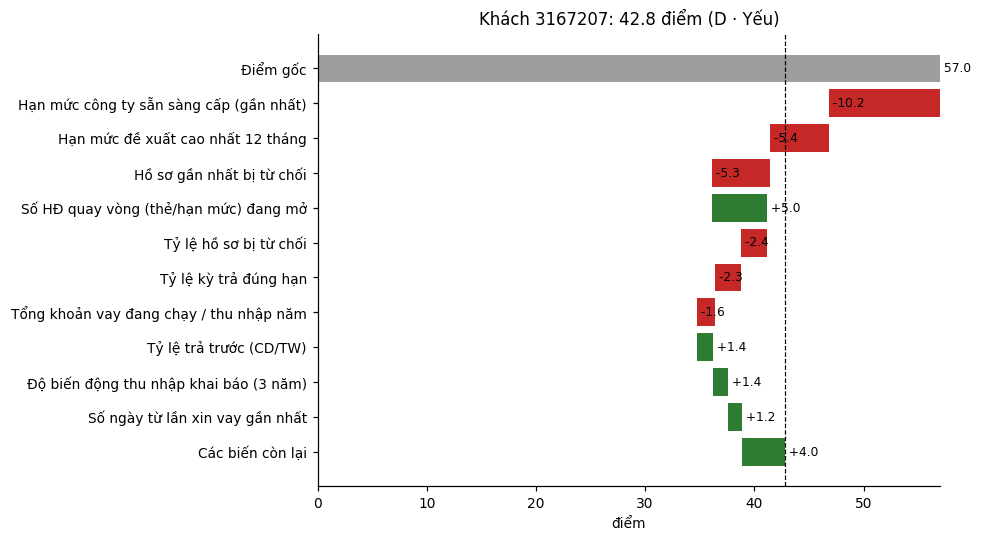

In [32]:
# Waterfall: điểm của một khách hạng D được tạo thành như thế nào
i = sc_f.index[sc_f.health_band.eq("D")][0]
contrib = (-M["factor"] * S_f.loc[i]).sort_values(key=abs, ascending=False)
top_c = contrib.head(10); rest = contrib.iloc[10:].sum()
base_pts = cfg["base_score"] + M["factor"] * (-b_f[0] - M["ref"])
vals = [base_pts] + list(top_c.values) + [rest]
labels = ["Điểm gốc"] + [desc[f] for f in top_c.index] + ["Các biến còn lại"]
cum = np.cumsum([0] + vals[:-1])
fig, ax = plt.subplots(figsize=(9, 5))
for k, (v, c0) in enumerate(zip(vals, cum)):
    ax.barh(k, v, left=c0 if k else 0, color="#9e9e9e" if k == 0 else ("#2e7d32" if v > 0 else "#c62828"))
    ax.text((c0 if k else 0) + v, k, f" {v:+.1f}" if k else f" {v:.1f}", va="center", fontsize=8)
ax.set_yticks(range(len(vals))); ax.set_yticklabels(labels); ax.invert_yaxis()
ax.axvline(sc_f.financial_health_score[i], color="k", ls="--", lw=.8)
ax.set_title(f"Khách {sc_f.skp_client[i]}: {sc_f.financial_health_score[i]:.1f} điểm ({sc_f.band_name[i]})")
ax.set_xlabel("điểm"); plt.tight_layout(); plt.show()

# Câu 5 · Bằng chứng phương pháp chấm điểm hợp lý
## Bước 9 · Kiểm định (`validate_scorecard`)
- **9a. Hiệu quả:** AUC, Gini, KS, tỷ lệ khách xấu nằm trong 10% điểm thấp nhất; từng mốc; PSI giữa tập huấn luyện và tập kiểm chứng.
- **9b. Hạng:** tỷ lệ xấu phải tăng dần từ A đến E.
- **9c. Logic:** chiều tác động của mỗi biến so với kỳ vọng nghiệp vụ.
- **9d. Bỏ từng nhóm biến:** huấn luyện lại mô hình khi không có nhóm đó, đo mức AUC giảm.
- **9e. Độ nhạy:** dời ngưỡng hạng ±2 điểm; đổi PDO.
- **9f. Dữ liệu độc lập:** CALL là nguồn duy nhất có dữ liệu sau ngày chấm. Kiểm tra xem cuộc gọi mã OWN* (trông như nhắc nợ) có phản ánh rủi ro thật không trước khi dùng làm thước đo.

In [33]:
rep = hp.validate_scorecard(M, cfg, dev, oot, sc_dev, sc_oot, S_oot, con, sc_f, final)
display(Markdown("**9a. Hiệu quả**"), rep["performance"])

[ 2102s] Bước 9 – hiệu quả:
                  Tap    AUC   Gini     KS  Bat_xau_top10  PSI_so_voi_huan_luyen
   Huấn luyện (5 mốc) 0.7693 0.5387 0.3967         0.3721                    NaN
       mốc 2024-02-01 0.7504 0.5007 0.3834         0.3399                    NaN
       mốc 2024-04-01 0.7635 0.5271 0.3834         0.3788                    NaN
       mốc 2024-06-01 0.7637 0.5273 0.3848         0.3842                    NaN
       mốc 2024-08-01 0.7654 0.5307 0.3964         0.3651                    NaN
       mốc 2024-10-01 0.7829 0.5659 0.4447         0.3639                    NaN
Kiểm chứng 2024-12-01 0.6746 0.3492 0.2782         0.2252                 0.1017


[ 2102s] Hạng (kiểm chứng), tỷ lệ xấu tăng dần A→E: True
             so_khach  ty_le_xau  diem_tb  ty_trong
health_band                                        
A              148376     0.0101  75.7463    0.2540
B               59529     0.0157  61.0037    0.1019
C               91624     0.0199  54.2250    0.1569
D               48734     0.0273  45.9164    0.0834
E               35385     0.0609  28.2395    0.0606
N              200409     0.0454  40.4441    0.3431


[ 2102s] Logic chiều tác động – biến không đạt: []


[ 2102s] Bỏ từng nhóm:
                   bo_nhom  so_bien_bo  AUC_con_lai  AUC_giam
6. Áp lực vay & độ tin cậy          14       0.6569    0.0177
     4. Lịch sử thanh toán           7       0.6582    0.0164
     5. Dự phòng tài chính           4       0.6720    0.0026
      7. Kế hoạch & bảo vệ           1       0.6736    0.0010
        2. Cân đối thu–chi           1       0.6742    0.0004
     1. Thu nhập & ổn định           7       0.6744    0.0002
           3. Gánh nặng nợ           3       0.6747   -0.0001


[ 2102s] Độ nhạy:
           kich_ban  ty_le_khach_doi_hang  ty_le_xau_A  ty_le_xau_E  van_tang_dan
Ngưỡng hạng -2 điểm                0.1021       0.0103       0.0652          True
Ngưỡng hạng +2 điểm                0.1032       0.0096       0.0571          True
           PDO = 10                0.1758       0.0082       0.0711          True
           PDO = 20                0.1013       0.0107       0.0562          True


[ 2102s] Dữ liệu độc lập (CALL mã OWN*, khách đang vay): AUC theo lịch sử trễ 0.496, theo điểm 0.496 → KHÔNG dùng được làm thước đo rủi ro
                    so_khach  ty_le_bi_goi_OWN  ty_le_noi_dung_tra_no
tre_12_thang                                                         
0 kỳ trễ              577148            0.0311                 0.0091
1 kỳ trễ                8360            0.0348                 0.0075
Chưa có kỳ đến hạn      9547            0.0459                 0.0114
≥ 2 kỳ trễ              9592            0.0139                 0.0014


**9a. Hiệu quả**

,Tap,AUC,Gini,KS,Bat_xau_top10,PSI_so_voi_huan_luyen
0,Huấn luyện (5 mốc),0.7693,0.5387,0.3967,0.3721,NaN
1,mốc 2024-02-01,0.7504,0.5007,0.3834,0.3399,NaN
2,mốc 2024-04-01,0.7635,0.5271,0.3834,0.3788,NaN
3,mốc 2024-06-01,0.7637,0.5273,0.3848,0.3842,NaN
4,mốc 2024-08-01,0.7654,0.5307,0.3964,0.3651,NaN
5,mốc 2024-10-01,0.7829,0.5659,0.4447,0.3639,NaN
6,Kiểm chứng 2024-12-01,0.6746,0.3492,0.2782,0.2252,0.1017


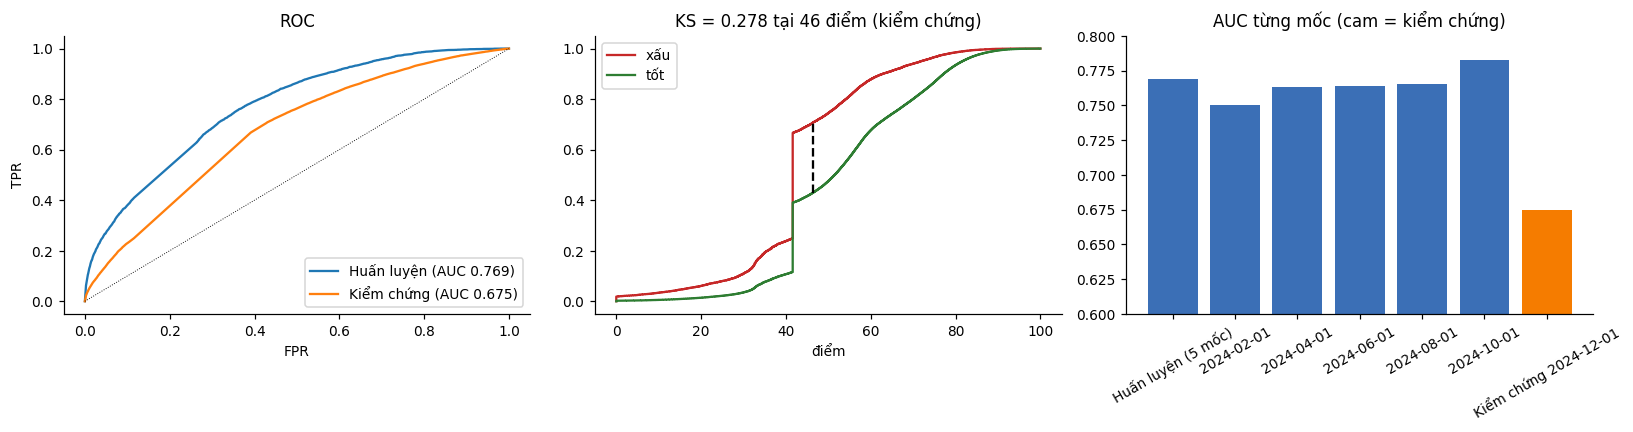

In [34]:
from sklearn.metrics import roc_curve
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for d, s, lab in [(dev, sc_dev, "Huấn luyện"), (oot, sc_oot, "Kiểm chứng")]:
    fpr, tpr, _ = roc_curve(d.bad, -s.financial_health_score)
    axes[0].plot(fpr, tpr, label=f"{lab} (AUC {np.trapz(tpr, fpr):.3f})")
axes[0].plot([0, 1], [0, 1], "k:", lw=.6); axes[0].legend(); axes[0].set_title("ROC"); axes[0].set_xlabel("FPR"); axes[0].set_ylabel("TPR")
s = np.sort(sc_oot.financial_health_score.values); yb = oot.bad.values[np.argsort(sc_oot.financial_health_score.values)]
cb, cg = np.cumsum(yb) / yb.sum(), np.cumsum(1 - yb) / (1 - yb).sum()
axes[1].plot(s, cb, label="xấu", color="#c62828"); axes[1].plot(s, cg, label="tốt", color="#2e7d32")
k = np.argmax(cb - cg); axes[1].vlines(s[k], cg[k], cb[k], color="k", ls="--")
axes[1].set_title(f"KS = {(cb - cg)[k]:.3f} tại {s[k]:.0f} điểm (kiểm chứng)"); axes[1].legend(); axes[1].set_xlabel("điểm")
pf = rep["performance"]; pf = pf[pf.Tap.str.contains("mốc|Kiểm")]
axes[2].bar(pf.Tap.str.replace("  mốc ", ""), pf.AUC, color=["#3b6fb6"] * (len(pf) - 1) + ["#f57c00"])
axes[2].set_ylim(.6, .8); axes[2].set_title("AUC từng mốc (cam = kiểm chứng)"); axes[2].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

**9b. Hạng (kiểm chứng)** — tỷ lệ xấu tăng dần A→E: **True**

,so_khach,ty_le_xau,diem_tb,ty_trong
health_band,,,,
A,148376,0.0101,75.7463,0.2540
B,59529,0.0157,61.0037,0.1019
C,91624,0.0199,54.2250,0.1569
D,48734,0.0273,45.9164,0.0834
E,35385,0.0609,28.2395,0.0606
N,200409,0.0454,40.4441,0.3431


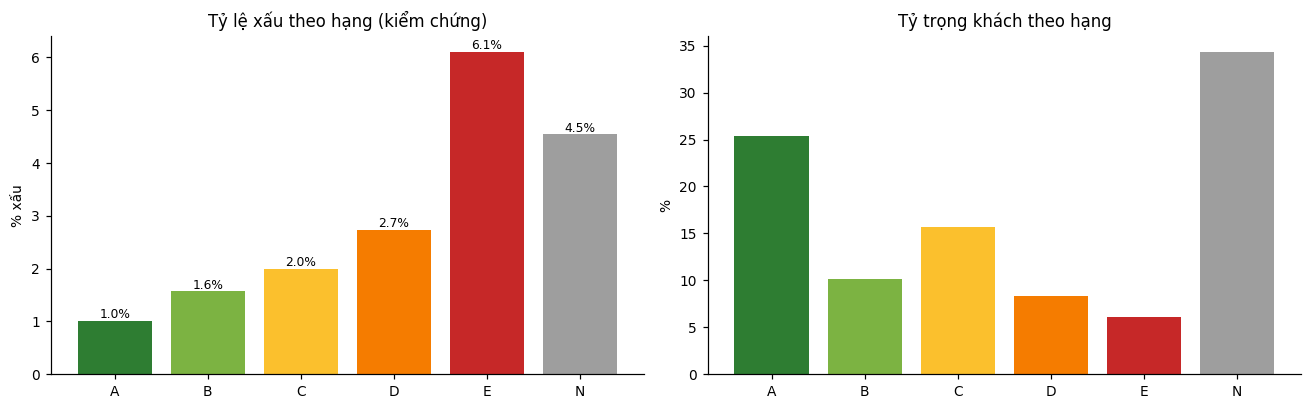

In [35]:
bt = rep["bands"].reindex(list("ABCDEN"))
display(Markdown(f"**9b. Hạng (kiểm chứng)** — tỷ lệ xấu tăng dần A→E: **{rep['band_monotonic']}**"), bt)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(bt.index, bt.ty_le_xau * 100, color=[BAND_COLORS[b] for b in bt.index])
for i, v in enumerate(bt.ty_le_xau): axes[0].text(i, v * 100, f"{v:.1%}", ha="center", va="bottom", fontsize=8)
axes[0].set_title("Tỷ lệ xấu theo hạng (kiểm chứng)"); axes[0].set_ylabel("% xấu")
axes[1].bar(bt.index, bt.ty_trong * 100, color=[BAND_COLORS[b] for b in bt.index]); axes[1].set_title("Tỷ trọng khách theo hạng"); axes[1].set_ylabel("%")
plt.tight_layout(); plt.show()

In [36]:
display(Markdown("**9c. Logic chiều tác động** (biến có ràng buộc phải 'Đạt')"),
        rep["logic"].sort_values(["rang_buoc", "nhom"], ascending=[False, True]))

**9c. Logic chiều tác động** (biến có ràng buộc phải 'Đạt')

,bien,mo_ta,nhom,rang_buoc,tuong_quan_gia_tri_vs_rui_ro,dung_chieu
24,n_inst_late_12m,Số kỳ trễ trong 12 tháng,4. Lịch sử thanh toán,1,0.9705,Đạt
25,n_inst_late_6m,Số kỳ trễ trong 6 tháng,4. Lịch sử thanh toán,1,0.9841,Đạt
26,late_rate_last3,Tỷ lệ trễ trong 3 HĐ gần nhất,4. Lịch sử thanh toán,1,0.9846,Đạt
31,ever_writeoff,Từng bị xóa nợ,4. Lịch sử thanh toán,1,0.4673,Đạt
2,last_app_rejected,Hồ sơ gần nhất bị từ chối,6. Áp lực vay & độ tin cậy,1,0.9863,Đạt
6,refused_ratio,Tỷ lệ hồ sơ bị từ chối,6. Áp lực vay & độ tin cậy,1,0.8256,Đạt
12,inc_cv,Độ biến động thu nhập khai báo (3 năm),1. Thu nhập & ổn định,0,0.8457,—
16,income_years_declared,Số năm có khai báo thu nhập,1. Thu nhập & ổn định,0,-0.2134,—
22,n_income_types,Số loại nguồn thu nhập đã khai,1. Thu nhập & ổn định,0,0.3220,—
28,inc_growth,Thu nhập mới nhất / cũ nhất (3 năm),1. Thu nhập & ổn định,0,-0.3183,—


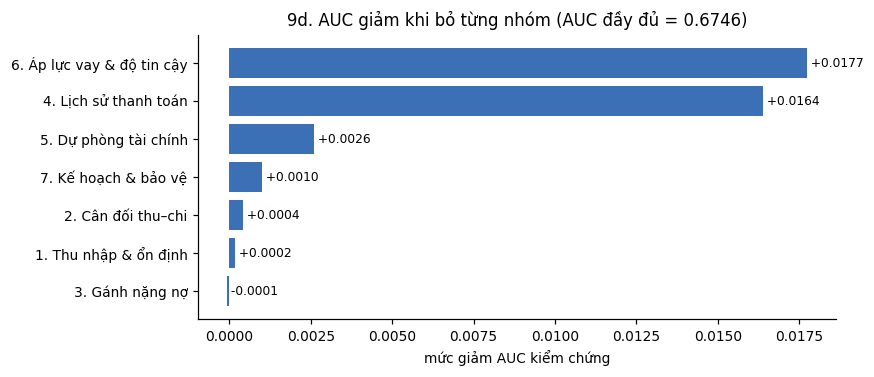

**9e. Độ nhạy**

,kich_ban,ty_le_khach_doi_hang,ty_le_xau_A,ty_le_xau_E,van_tang_dan
0,Ngưỡng hạng -2 điểm,0.1021,0.0103,0.0652,True
1,Ngưỡng hạng +2 điểm,0.1032,0.0096,0.0571,True
2,PDO = 10,0.1758,0.0082,0.0711,True
3,PDO = 20,0.1013,0.0107,0.0562,True


In [37]:
dg = rep["drop_group"].sort_values("AUC_giam")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(dg.bo_nhom, dg.AUC_giam, color="#3b6fb6")
for i, v in enumerate(dg.AUC_giam): ax.text(v, i, f" {v:+.4f}", va="center", fontsize=8)
ax.set_title(f"9d. AUC giảm khi bỏ từng nhóm (AUC đầy đủ = {rep['base_auc']:.4f})"); ax.set_xlabel("mức giảm AUC kiểm chứng")
plt.tight_layout(); plt.show()
display(Markdown("**9e. Độ nhạy**"), rep["sensitivity"])

**9f. Kiểm tra CALL làm dữ liệu độc lập** (khách đang có khoản vay tại ngày chấm, cuộc gọi trong 6 tháng sau)

- AUC dự báo "bị gọi mã OWN*" bằng **số kỳ trễ 12 tháng** (lịch sử trễ thật): **0.496**
- AUC bằng Financial Health Score: 0.496
- Kết luận: **KHÔNG dùng được làm thước đo rủi ro**

,so_khach,ty_le_bi_goi_OWN,ty_le_noi_dung_tra_no
tre_12_thang,,,
Chưa có kỳ đến hạn,9547,0.0459,0.0114
0 kỳ trễ,577148,0.0311,0.0091
1 kỳ trễ,8360,0.0348,0.0075
≥ 2 kỳ trễ,9592,0.0139,0.0014


Loại ưu đãi (offer_type) của các cuộc gọi mã OWN*:

,offer_type,n,ty_trong
0,PRODUCT OFFER,144626,0.8339
1,PTO,14258,0.0822
2,PR1,9272,0.0535
3,PR2,3692,0.0213
4,PR3,1576,0.0091


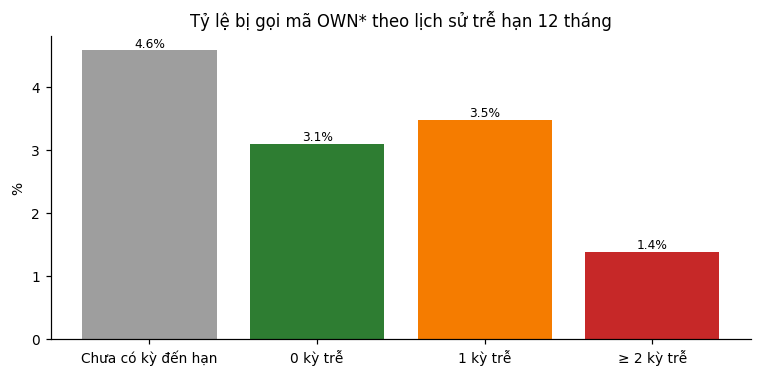

In [38]:
ind = rep["independent"].reindex(["Chưa có kỳ đến hạn", "0 kỳ trễ", "1 kỳ trễ", "≥ 2 kỳ trễ"])
display(Markdown(f"""**9f. Kiểm tra CALL làm dữ liệu độc lập** (khách đang có khoản vay tại ngày chấm, cuộc gọi trong 6 tháng sau)

- AUC dự báo "bị gọi mã OWN*" bằng **số kỳ trễ 12 tháng** (lịch sử trễ thật): **{rep['independent_auc_late']:.3f}**
- AUC bằng Financial Health Score: {rep['independent_auc']:.3f}
- Kết luận: **{'dùng được' if rep['independent_usable'] else 'KHÔNG dùng được làm thước đo rủi ro'}**"""), ind)
display(Markdown("Loại ưu đãi (offer_type) của các cuộc gọi mã OWN*:"), rep["own_offer"])
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(ind.index, ind.ty_le_bi_goi_OWN * 100, color=["#9e9e9e", "#2e7d32", "#f57c00", "#c62828"])
for i, v in enumerate(ind.ty_le_bi_goi_OWN): ax.text(i, v * 100, f"{v:.1%}", ha="center", va="bottom", fontsize=8)
ax.set_title("Tỷ lệ bị gọi mã OWN* theo lịch sử trễ hạn 12 tháng"); ax.set_ylabel("%")
plt.tight_layout(); plt.show()

**Diễn giải 9f:** nếu OWN* là cuộc gọi nhắc nợ, khách từng trễ hạn phải bị gọi nhiều hơn rõ rệt. Dữ liệu cho thấy ngược lại: tỷ lệ bị gọi gần như như nhau (khách trễ ≥ 2 kỳ còn bị gọi ít hơn), và phần lớn cuộc gọi OWN* mang loại ưu đãi *PRODUCT OFFER*, tức cuộc gọi chào bán.
Vì vậy CALL **không** được dùng làm bằng chứng độc lập. Bằng chứng chính của mô hình là **kiểm chứng ngoài thời gian** (9a–9b): dữ liệu 12/2024–01/2025 hoàn toàn không tham gia huấn luyện hay chọn biến.

## Bước 10 · Xuất và theo dõi (`export_and_monitor`)
Xuất file điểm có ngày chấm và phiên bản, kèm hành động gợi ý theo hạng; lưu mô hình và cấu hình; đo trôi dạt từng biến (PSI, tỷ lệ thiếu) so với tập huấn luyện; ghi lịch sử theo dõi.

**Lưu ý khi đọc PSI tại ngày chấm:** tập huấn luyện chỉ gồm khách **vừa được duyệt một HĐ trả góp mới** sau mỗi mốc (chỉ họ mới có nhãn tốt/xấu), còn ngày chấm gồm **toàn bộ khách**, kể cả khách bị từ chối, khách lâu không vay. Vì vậy PSI cao ở đây phản ánh **khác biệt tập khách**, không phải mô hình bị lỗi thời. Ô bên dưới tách phân bố điểm theo loại khách để thấy phần nào do khác biệt tập khách.

[ 2206s] Bước 10 – đã xuất 1,000,528 khách; PSI điểm so với huấn luyện 0.423
             so_khach  ty_trong
health_band                    
A              324326    0.3240
B              106002    0.1060
C              118628    0.1190
D              108038    0.1080
E              156672    0.1570
N              186862    0.1870
Biến trôi dạt nhiều nhất:
                 bien                                 mo_ta  thieu_huan_luyen  thieu_hien_tai    PSI      canh_bao
days_since_last_apply       Số ngày từ lần xin vay gần nhất            0.1470          0.0000 7.1680 Trôi dạt mạnh
n_products_applied_6m      Số loại sản phẩm xin vay 6 tháng            0.1470          0.0000 3.3280 Trôi dạt mạnh
      n_income_values     Số mức thu nhập khác nhau đã khai            0.2490          0.0000 2.1970 Trôi dạt mạnh
            n_on_time                    Số kỳ trả đúng hạn            0.1470          0.0000 1.9080 Trôi dạt mạnh
        refused_ratio                Tỷ lệ hồ sơ bị từ chối       

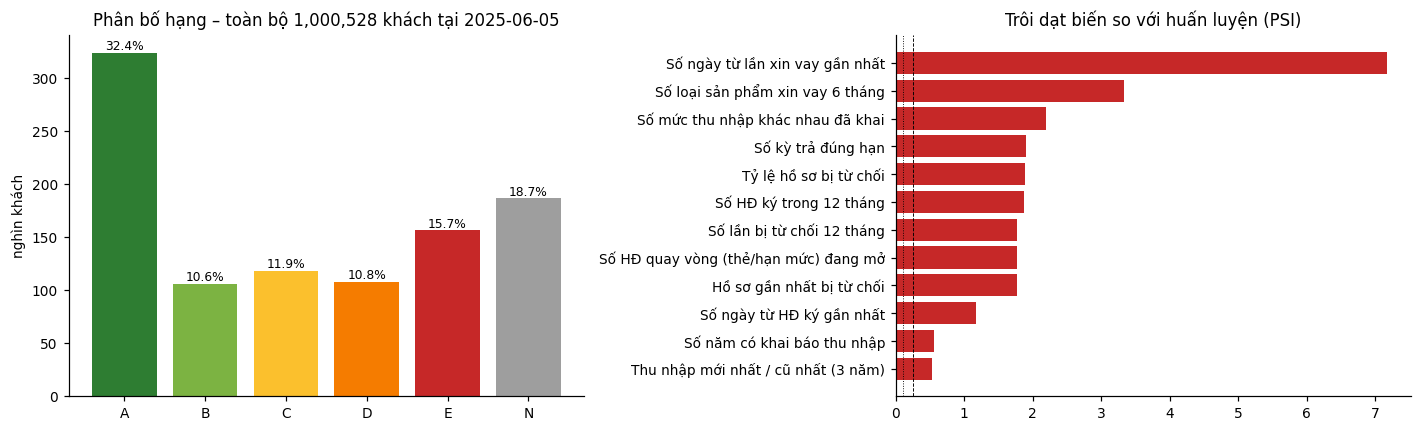

**Phân bố điểm theo loại khách**

,so_khach,PSI_diem_vs_huan_luyen,ty_trong_A,ty_trong_E
Hồ sơ gần nhất bị từ chối,"282,417",2.471,5.1%,24.9%
Ký HĐ trong 60 ngày gần nhất,"66,305",0.326,48.4%,13.1%
Toàn bộ khách,"1,000,528",0.423,32.4%,15.7%
Tập kiểm chứng 12/2024,"584,057",0.102,25.4%,6.1%


**Diễn giải và giới hạn:** khách có hồ sơ gần nhất bị từ chối (khoảng 28% danh mục) là nguồn lớn nhất của hạng E; nhóm này gần như vắng mặt trong tập huấn luyện vì chỉ khách được duyệt HĐ mới có nhãn.
Tuy nhiên ngay cả khách vừa ký HĐ cũng có tỷ trọng E cao hơn tập kiểm chứng, nên phân bố điểm tháng 6/2025 khác cuối 2024 thật sự. Dữ liệu chưa có kết quả trả nợ sau 06/2025 để kiểm chứng tỷ lệ xấu thực của từng hạng tại ngày chấm.
**Khuyến nghị:** giữ thứ hạng (mô hình đã chứng minh xếp hạng đúng trên dữ liệu ngoài thời gian), nhưng hiệu chỉnh lại ngưỡng hạng khi có 4 kỳ trả nợ của các HĐ ký sau 06/2025; theo dõi PSI hàng tháng theo bảng lịch sử bên dưới.

**Hành động gợi ý theo hạng**

,hang,hanh_dong
0,A · Rất khỏe,"Ưu tiên tăng hạn mức, mời sản phẩm giá trị cao..."
1,B · Khỏe,"Duy trì, bán thêm có chọn lọc với hạn mức hiện..."
2,C · Trung bình,Cho vay có kiểm soát: sản phẩm có trả trước (C...
3,D · Yếu,"Hạn chế cấp mới, chỉ khoản nhỏ có trả trước; t..."
4,E · Rủi ro cao,"Không cấp tín dụng mới; ưu tiên nhắc nợ, tư vấ..."
5,N · Chưa đủ lịch sử trả nợ,"Hạn mức nhỏ (BNPL/CD), tăng dần hạn mức sau mỗ..."


**Lịch sử theo dõi**

,score_date,version,so_khach,diem_tb,PSI_diem,ty_trong_A,ty_trong_B,ty_trong_C,ty_trong_D,ty_trong_E,ty_trong_N,so_bien_troi_dat,AUC_kiem_chung
0,2025-06-05,FH-GB-v1.0,1000528,51.1921,0.3964,0.2930,0.1119,0.1175,0.1113,0.1561,0.2102,17,0.6738
1,2025-06-05,FH-GB-v1.1,1000528,51.8775,0.4232,0.3242,0.1059,0.1186,0.1080,0.1566,0.1868,18,0.6746


**File kết quả:** `D:\Thi\BI10_ROUND02_DATASET\solution\out_team\pipeline\FH-GB-v1.1\10_customer_financial_health.csv`

,skp_client,score_date,score_version,financial_health_score,diem_nhom_1,diem_cong_tru_nhom_1,diem_nhom_2,diem_cong_tru_nhom_2,diem_nhom_3,diem_cong_tru_nhom_3,diem_nhom_4,diem_cong_tru_nhom_4,diem_nhom_5,diem_cong_tru_nhom_5,diem_nhom_6,diem_cong_tru_nhom_6,diem_nhom_7,diem_cong_tru_nhom_7,xac_suat_xau,health_band,band_name,data_completeness,ly_do_tru_diem_1,diem_tru_1,diem_manh_1,diem_cong_1,ly_do_tru_diem_2,diem_tru_2,diem_manh_2,diem_cong_2,ly_do_tru_diem_3,diem_tru_3,diem_manh_3,diem_cong_3,ty_le_chi_tieu_co_du_lieu,hanh_dong_goi_y
0,77898974,2025-06-05,FH-GB-v1.1,39.2000,93.0000,1.9600,77.6000,1.5400,12.5000,-0.7300,72.6000,-0.6100,77.3000,2.5600,6.5000,-23.2500,80.4000,0.7200,0.0220,E,E · Rủi ro cao,Một phần (1 HĐ đã qua ≥ 3 kỳ trả),Hạn mức công ty sẵn sàng cấp (gần nhất),-12.1000,Hạn mức hiện tại / 6 tháng trước,2.2000,Hồ sơ gần nhất bị từ chối,-6.1000,Tỷ lệ trả trước (CD/TW),1.6000,Hạn mức đề xuất cao nhất 12 tháng,-5.9000,Thu nhập còn lại sau tiền góp hàng tháng,1.5000,0.8100,"Không cấp tín dụng mới; ưu tiên nhắc nợ, tư vấ..."
1,78285025,2025-06-05,FH-GB-v1.1,54.1000,67.4000,-0.1600,44.4000,0.1900,75.6000,7.0600,86.8000,4.0000,39.9000,-5.7200,34.6000,-8.6300,71.4000,0.3600,0.0112,C,C · Trung bình,Đầy đủ (≥ 2 HĐ đã qua ≥ 3 kỳ trả),Hạn mức công ty sẵn sàng cấp (gần nhất),-6.0000,Số HĐ quay vòng (thẻ/hạn mức) đang mở,4.8000,Số loại sản phẩm xin vay 6 tháng,-4.5000,Hạn mức hiện tại / 6 tháng trước,3.6000,Hạn mức đề xuất cao nhất 12 tháng,-3.7000,Tổng khoản vay đang chạy / thu nhập năm,2.3000,0.9700,Cho vay có kiểm soát: sản phẩm có trả trước (C...
2,79184114,2025-06-05,FH-GB-v1.1,58.1000,73.3000,0.3200,42.0000,0.0900,23.5000,0.6200,85.7000,3.6400,89.7000,5.3000,33.3000,-9.3200,73.6000,0.4500,0.0093,B,B · Khỏe,Đầy đủ (≥ 2 HĐ đã qua ≥ 3 kỳ trả),Số lần bị từ chối 12 tháng,-6.1000,Tỷ lệ trả trước (CD/TW),2.2000,Hạn mức đề xuất cao nhất 12 tháng,-3.0000,Số HĐ ký trong 12 tháng,1.6000,Tỷ lệ hồ sơ bị từ chối,-3.0000,Số kỳ trả đúng hạn,1.6000,0.9700,"Duy trì, bán thêm có chọn lọc với hạn mức hiện..."
3,79806953,2025-06-05,FH-GB-v1.1,25.0000,30.4000,-3.2400,29.1000,-0.4400,19.3000,0.1000,78.6000,1.3500,13.8000,-11.5200,15.1000,-18.7700,74.0000,0.4600,0.0417,E,E · Rủi ro cao,Đầy đủ (≥ 2 HĐ đã qua ≥ 3 kỳ trả),Hạn mức công ty sẵn sàng cấp (gần nhất),-12.6000,Hồ sơ gần nhất bị từ chối,1.3000,Hạn mức đề xuất cao nhất 12 tháng,-7.0000,Số kỳ trễ trong 12 tháng,0.8000,Tiền trả trước trung bình,-4.8000,Số năm có khai báo thu nhập,0.7000,0.9200,"Không cấp tín dụng mới; ưu tiên nhắc nợ, tư vấ..."
4,79810779,2025-06-05,FH-GB-v1.1,72.4000,85.6000,1.3400,70.3000,1.2400,93.1000,9.2300,77.8000,1.1000,53.2000,-2.7900,63.9000,6.6000,29.6000,-1.3500,0.0048,A,A · Rất khỏe,Đầy đủ (≥ 2 HĐ đã qua ≥ 3 kỳ trả),Số ngày từ lần xin vay gần nhất,-2.1000,Số HĐ quay vòng (thẻ/hạn mức) đang mở,7.2000,Tỷ lệ trả trước (CD/TW),-1.9000,Hạn mức công ty sẵn sàng cấp (gần nhất),6.9000,Tỷ lệ HĐ có mua bảo hiểm khoản vay,-1.3000,Số năm có khai báo thu nhập,1.9000,0.8600,"Ưu tiên tăng hạn mức, mời sản phẩm giá trị cao..."


In [39]:
res, mon = hp.export_and_monitor(M, cfg, final, sc_f, expl, pts_f, dev, sc_dev, rep)
dist = res.health_band.value_counts().reindex(list("ABCDEN"))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(dist.index, dist.values / 1e3, color=[BAND_COLORS[b] for b in dist.index])
for i, v in enumerate(dist.values): axes[0].text(i, v / 1e3, f"{v / dist.sum():.1%}", ha="center", va="bottom", fontsize=8)
axes[0].set_title(f"Phân bố hạng – toàn bộ {len(res):,} khách tại {cfg['score_date']}"); axes[0].set_ylabel("nghìn khách")
mm = mon.head(12)[::-1]
axes[1].barh(mm.mo_ta, mm.PSI, color=["#c62828" if p > .25 else "#fbc02d" if p > .1 else "#2e7d32" for p in mm.PSI])
axes[1].axvline(.1, color="k", ls=":", lw=.6); axes[1].axvline(.25, color="k", ls="--", lw=.6)
axes[1].set_title("Trôi dạt biến so với huấn luyện (PSI)"); plt.tight_layout(); plt.show()
from scorecard import psi
grp = {"Hồ sơ gần nhất bị từ chối": final.last_app_rejected.eq(1).values,
       "Ký HĐ trong 60 ngày gần nhất": final.days_since_last_signed.le(60).values,
       "Toàn bộ khách": np.ones(len(final), bool)}
cmp_ = pd.DataFrame({k: {"so_khach": m.sum(), "PSI_diem_vs_huan_luyen": psi(sc_dev.financial_health_score.values, res.financial_health_score.values[m]),
                         **{f"ty_trong_{b}": (res.health_band.values[m] == b).mean() for b in "AE"}} for k, m in grp.items()}).T
cmp_.loc["Tập kiểm chứng 12/2024"] = [len(sc_oot), psi(sc_dev.financial_health_score.values, sc_oot.financial_health_score.values),
                                     (sc_oot.health_band == "A").mean(), (sc_oot.health_band == "E").mean()]
display(Markdown("**Phân bố điểm theo loại khách**"), cmp_.style.format({"so_khach": "{:,.0f}", "PSI_diem_vs_huan_luyen": "{:.3f}",
                                                                          "ty_trong_A": "{:.1%}", "ty_trong_E": "{:.1%}"}))
display(Markdown("""**Diễn giải và giới hạn:** khách có hồ sơ gần nhất bị từ chối (khoảng 28% danh mục) là nguồn lớn nhất của hạng E; nhóm này gần như vắng mặt trong tập huấn luyện vì chỉ khách được duyệt HĐ mới có nhãn.
Tuy nhiên ngay cả khách vừa ký HĐ cũng có tỷ trọng E cao hơn tập kiểm chứng, nên phân bố điểm tháng 6/2025 khác cuối 2024 thật sự. Dữ liệu chưa có kết quả trả nợ sau 06/2025 để kiểm chứng tỷ lệ xấu thực của từng hạng tại ngày chấm.
**Khuyến nghị:** giữ thứ hạng (mô hình đã chứng minh xếp hạng đúng trên dữ liệu ngoài thời gian), nhưng hiệu chỉnh lại ngưỡng hạng khi có 4 kỳ trả nợ của các HĐ ký sau 06/2025; theo dõi PSI hàng tháng theo bảng lịch sử bên dưới."""))
display(Markdown("**Hành động gợi ý theo hạng**"),
        pd.DataFrame({"hang": list(cfg["band_name"].values()), "hanh_dong": list(cfg["band_action"].values())}))
display(Markdown("**Lịch sử theo dõi**"), pd.read_csv(HERE / "out_team" / "pipeline" / "monitoring_history.csv"))
display(Markdown(f"**File kết quả:** `{cfg['out'] / '10_customer_financial_health.csv'}`"), res.head())

## Tổng kết

In [40]:
p = rep["performance"].set_index("Tap")
oot_row = p.iloc[-1]
display(Markdown(f"""
| Chỉ tiêu | Giá trị |
|---|---|
| Số biến trong mô hình | {len(M['feats'])} (từ 57 biến ứng viên) |
| AUC / Gini kiểm chứng 12/2024 | {oot_row.AUC:.3f} / {oot_row.Gini:.3f} (scorecard cũ: 0.661 / 0.322) |
| KS kiểm chứng | {oot_row.KS:.3f} |
| Tỷ lệ khách xấu nằm trong 10% điểm thấp nhất | {oot_row.Bat_xau_top10:.1%} |
| PSI điểm (huấn luyện → kiểm chứng) | {oot_row.PSI_so_voi_huan_luyen:.3f} |
| Tỷ lệ xấu tăng dần A→E | {rep['band_monotonic']} |
| Biến sai chiều nghiệp vụ | {int((rep['logic'].dung_chieu == 'KHÔNG ĐẠT').sum())} |
| Dữ liệu độc lập (CALL mã OWN*) | không phản ánh rủi ro (AUC theo lịch sử trễ {rep['independent_auc_late']:.3f}) → không dùng làm bằng chứng |
| Nhóm quan trọng nhất (bỏ đi thì AUC giảm nhiều nhất) | {rep['drop_group'].iloc[0].bo_nhom} |
"""))


| Chỉ tiêu | Giá trị |
|---|---|
| Số biến trong mô hình | 37 (từ 57 biến ứng viên) |
| AUC / Gini kiểm chứng 12/2024 | 0.675 / 0.349 (scorecard cũ: 0.661 / 0.322) |
| KS kiểm chứng | 0.278 |
| Tỷ lệ khách xấu nằm trong 10% điểm thấp nhất | 22.5% |
| PSI điểm (huấn luyện → kiểm chứng) | 0.102 |
| Tỷ lệ xấu tăng dần A→E | True |
| Biến sai chiều nghiệp vụ | 0 |
| Dữ liệu độc lập (CALL mã OWN*) | không phản ánh rủi ro (AUC theo lịch sử trễ 0.496) → không dùng làm bằng chứng |
| Nhóm quan trọng nhất (bỏ đi thì AUC giảm nhiều nhất) | 6. Áp lực vay & độ tin cậy |
